# Modelo *early* de morosidad — sistema bancario peruano

**Objetivo.** Predecir el evento `predictiva_early` sobre una cartera de 130,184 clientes con información de buró (RCC), abril–noviembre 2021, y entregar un modelo que pueda ir a un comité de riesgos: con su validación fuera de tiempo, su justificación de variables y su criterio de decisión.

---

### ⚠️ Nota para el lector

Este notebook contiene **todo el proyecto**, de principio a fin, en orden de ejecución. Para la reproducibilidad se tiene `SEED` y `SAMPLE_FRAC` (por si quieres replicarlo con una muestra menor).

**Lo que este notebook no resuelve:** la bitácora no documenta el horizonte del evento ni su definición exacta, hay solo 8 meses de historia y la base no trae ingresos, comportamiento interno ni clientes rechazados. Todo eso acota lo que se puede afirmar y está señalado donde corresponde.

**Se usan reglas de negocio que se prueban empíricamente en la sección 6.**


### Índice

| # | Sección | Qué se decide ahí |
|---|---|---|
| 1 | Configuración | Semilla y tamaño de muestra|
| 2 | Carga y calidad de datos | Cómo viene el archivo y por qué tratamiento de outliers |
| 3 | Control de fuga de información | Si alguna variable conoce el futuro (data leakage) |
| 4 | Partición temporal | TRAIN / TEST / OOT, y por qué no es aleatoria |
| 5 | EDA | comportamiento del evento |
| 6 | WoE, IV y selección de variables | Filtros estadísticos y verificación de las reglas de negocio |
| 7 | Modelo: regresión logística | Forward con restricción de signo |
| 8 | Challengers | Árbol y LightGBM |
| 9 | Validación | CV, gap train/validación, OOT, calibración |
| 10 | Decisión del modelo | Matriz ponderada y su sensibilidad |
| 11 | Scorecard, bandas y punto de corte | Cómo se usa |
| 12 | Resultado final | Celda única con los números de entrega |
| 13 | Exportación | Se exporta el modelo a un aplicativo que pueda ser usado |

## 1. Configuración

In [1]:
# Requisitos: pandas numpy scipy scikit-learn statsmodels optbinning lightgbm matplotlib seaborn
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy import stats
from optbinning import OptimalBinning
from lightgbm import LGBMClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve, log_loss
from statsmodels.stats.outliers_influence import variance_inflation_factor

# ─────────────────────────────────────────────────────────────────────
# entorno
SEED = 42
SAMPLE_FRAC = 1          # 1.0 = base completa. La muestra solo acelera el desarrollo.
RUTA_CSV = r"./proyecto_morosidad_early/Prueba_Modelos_Caso_Morosidad.csv"
# ─────────────────────────────────────────────────────────────────────

# Localiza el CSV sin depender del directorio desde el que se abra el notebook
_nombre = Path(RUTA_CSV).name
CSV = next((p for p in [Path(RUTA_CSV), Path(_nombre), Path("data") / _nombre, Path("..") / _nombre,
                        Path("/mnt/user-data/uploads") / _nombre] if p.exists()), Path(RUTA_CSV))

pd.set_option("display.width", 170, "display.max_columns", 40, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

print(f"Datos      : {CSV}  (existe: {CSV.exists()})")
print(f"SEED       : {SEED}")

(CVXPY) Nov 16 01:39:30 PM: Encountered unexpected exception importing solver GLOP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.15.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Nov 16 01:39:30 PM: Encountered unexpected exception importing solver PDLP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.15.0. Please open a feature request on cvxpy to enable support for this version.')


Datos      : proyecto_morosidad_early\Prueba_Modelos_Caso_Morosidad.csv  (existe: True)
SEED       : 42


## 2. Carga y calidad de datos

Se lee primero **como texto puro** (`dtype=str`) para ver cómo viene el archivo antes de transformarlo. Dejar que pandas adivine tipos aquí oculta los problemas en lugar de mostrarlos.

In [2]:
raw = pd.read_csv(CSV, encoding="latin-1", dtype=str, low_memory=False)
print(f"Dimensión: {raw.shape}  |  ¿un registro por cliente?: {raw['serie'].is_unique}")

# (a) Faltantes disfrazados: llegan como " " (espacio), que pandas no reconoce como nulo
blancos = raw.apply(lambda s: s.str.strip().eq("").sum())/raw.shape[0]
print(f"\n(a) Columnas con blancos ' ' en lugar de nulos: {(blancos > 0).sum()} de {raw.shape[1]}")
display(blancos[blancos > 0].sort_values(ascending=False).head(5).to_frame("% celdas en blanco"))

# (b) Números en notación científica guardados como texto (son ceros, no faltantes)
print("(b) Ejemplo de notación científica en texto:",
      raw["DOTROS_DTOTAL"][raw["DOTROS_DTOTAL"].str.contains("E-", na=False)].head(2).tolist())

# (c) ¿Qué columnas tienen contenido realmente no numérico?
#     Si al forzar a numérico aparecen nulos nuevos, la columna contiene texto.
es_texto = lambda s: pd.to_numeric(s.str.strip().replace("", np.nan), errors="coerce").isna().sum() > s.str.strip().replace("", np.nan).isna().sum()
COLS_TEXTO = [c for c in raw.columns if es_texto(raw[c])]
print(f"\n(c) Columnas de texto ({len(COLS_TEXTO)}): {sorted(COLS_TEXTO)}")
print("    ESTADO_CIVIL viene codificado numéricamente, por eso no aparece aquí:",
      "ESTADO_CIVIL" not in COLS_TEXTO)

Dimensión: (130184, 157)  |  ¿un registro por cliente?: True

(a) Columnas con blancos ' ' en lugar de nulos: 102 de 157


,% celdas en blanco
MARCA_HIP3,0.9661
MARCA_HIP6,0.9653
MARCA_HIP12,0.9640
CONV_PREST,0.9458
CONV_DEUDA,0.9458


(b) Ejemplo de notación científica en texto: ['1.82783245697269E-016', '-8.01242088204034E-017']

(c) Columnas de texto (6): ['DEPARTAMENTO', 'DISTRITO', 'GENERO', 'GRADO_INSTRUCCION', 'PROVINCIA', 'SITUACION_LABORAL']
    ESTADO_CIVIL viene codificado numéricamente, por eso no aparece aquí: True


### Hallazgos de calidad y su tratamiento

| Hallazgo | Por qué importa | Tratamiento |
|---|---|---|
| El CSV no es UTF-8 (`Ñ`, `º` en `GRADO_INSTRUCCION`) | la lectura corrompe las categorías | `encoding="latin-1"` |
| Los faltantes vienen como `" "` y los números como texto | pandas lee todo como `object`: ninguna variable sería usable | `strip()` → `NaN` → `to_numeric(errors="coerce")` |
| Notación científica (`-9.17E-017`) | parece texto raro, son ceros | `to_numeric` los convierte bien |
| `predictiva_early` tiene polaridad invertida (1 = Bueno) | modelar sin invertir daría signos y scores al revés | se crea `bad = 1 - predictiva_early` |

---

### Sobre la imputación de dato y Por qué NO se deberia hacer

Es la decisión de limpieza más importante del proyecto, y va en contra del reflejo habitual de rellenar con algún método.

**Los faltantes de esta base son estructurales, no errores.** Cuando `PROM_LINEA12` viene vacía no es que falte el dato: es que **el cliente no tiene tarjeta de crédito**. Lo mismo con las variables de convenio, hipotecario o garantías. Imputar la media ahí equivale a inventar un cliente que no existe, uno con una línea de tarjeta promedio sin tener tarjeta, y, peor, **borra la información**: la sección 5 muestra que la población sin tarjeta tiene una tasa de mora distinta, así que el hecho de no tener el dato *es* la señal.

**LOS NULOS TAMBIEN TIENEN INFORMACIÓN RELEVANTE**

Por lo tanto el tratamiento correcto es dejar el `NaN` y que el modelo lo trate como una categoría propia:
* En el **binning WoE** (sección 6), optbinning le asigna al tramo *Missing* su propio Weight of Evidence, estimado con la tasa de malos real de ese grupo.
* En **LightGBM**, el `NaN` se maneja de forma nativa: el algoritmo aprende hacia qué lado del split enviarlo.

Ninguna de las dos rutas necesita imputación, y ambas conservan la señal.

### Sobre los valores atípicos y por qué NO se tratan

Tampoco se winsoriza ni se recortan colas, por dos razones.

**La primera es que el binning ya lo resuelve.** Al discretizar en tramos, un valor extremo cae en el último bin y pesa exactamente igual que cualquier otro valor de ese bin. Un `GARAN_SALDO` de 5,000 y uno de 500,000 reciben el mismo WoE. El outlier deja de ser un problema de escala sin que haya que tocar el dato. Lo mismo vale para los árboles, que son invariantes a transformaciones monótonas: por eso tampoco se aplican logaritmos.

**La segunda es que recortar sería decidir qué dato es "raro" mirando la distribución**, y en riesgo de crédito las colas suelen ser justamente la población de interés. Un ratio de endeudamiento extremo no es ruido que convenga suavizar: es información.

> La consecuencia práctica es que la base llega al modelado **sin alterar un solo valor original**. Todo lo que hace la limpieza es corregir el formato con el que el archivo fue escrito.

In [3]:
# Limpieza explícita: formato, no contenido.
df = raw.copy()

# Columnas de texto: blancos -> NaN. Se recorre COLS_TEXTO y se fuerza astype(str) en lugar de
# preguntar por el dtype: pandas 3 infiere 'str' y no 'object', así que una condición
# df[c].dtype == object dejaría los blancos intactos y crearía una categoría fantasma.
for c in COLS_TEXTO:
    df[c] = df[c].astype(str).str.strip().replace({"": np.nan, "nan": np.nan, "None": np.nan})

for c in df.columns:                                   # el resto a numérico (' ' -> NaN por coerce)
    if c not in COLS_TEXTO:
        df[c] = pd.to_numeric(df[c], errors="coerce")

df["bad"] = 1 - df["predictiva_early"]                 # 1 = evento (moroso)

# Verificaciones: target binario y sin blancos residuales en las columnas de texto
assert df["predictiva_early"].isin([0, 1]).all()
assert (df["bad"] == 1 - df["predictiva_early"]).all()
residuales = {c: int(df[c].dropna().astype(str).str.strip().eq("").sum()) for c in COLS_TEXTO}
assert sum(residuales.values()) == 0, f"quedan blancos sin convertir: {residuales}"

print(f"Base limpia: {df.shape[0]:,} clientes x {df.shape[1]} columnas")
print(f"Evento (bad=1): {df.bad.sum():,} clientes ({df.bad.mean():.2%})")
print(f"Celdas nulas reconocidas: {df.isna().sum().sum():,}  (antes de limpiar: {raw.isna().sum().sum():,})")

Base limpia: 130,184 clientes x 158 columnas
Evento (bad=1): 9,398 clientes (7.22%)
Celdas nulas reconocidas: 3,484,023  (antes de limpiar: 0)


### Variables que se excluyen

Esta es una **decisión de política, no un resultado estadístico**, y por eso va declarada y con su costo medido (sección 10).

| Variable | Motivo |
|---|---|
| `GENERO` | atributo protegido |
| `ESTADO_CIVIL` | atributo protegido, correlaciona con género |
| `DEPARTAMENTO`, `PROVINCIA`, `DISTRITO` | proxies geográficos |
| `serie` | identificador, sin contenido predictivo |
| `PERIODO` | fecha de corte: el modelo aprendería la tendencia del mes, no el riesgo del cliente |

Sobre las tres primeras conviene ser preciso, porque la discusión cambia según el uso del modelo. Si bien en Perú , en el mercado financicero, no hay una norma que prohíba el género como predictor en un scoring, como sí ocurre con la ECOA en Estados Unidos; lo que Indecopi sanciona bajo el artículo 38 de la Ley 29571 es **negar o condicionar el acceso** por una categoría sin justificación objetiva. Si bien este modelo solo prioriza gestión de cobranza, la exposición es menor que si alimenta decisiones de línea o preaprobados. **Aquí se excluyen por criterio conservador**, el score puede terminar alimentando decisiones de acceso, y la sección 10 mide exactamente cuánto cuesta esa decisión. `EDAD` compite como cualquier otra variable.

In [4]:
EXCLUIDAS = ["GENERO", "ESTADO_CIVIL", "DEPARTAMENTO", "PROVINCIA", "DISTRITO", "serie", "PERIODO"]

CATEGORICAS = [c for c in COLS_TEXTO if c not in EXCLUIDAS]
NUMERICAS = [c for c in df.columns if c not in COLS_TEXTO + EXCLUIDAS + ["bad", "predictiva_early"]]
CANDIDATAS = NUMERICAS + CATEGORICAS

print(pd.Series({
    "columnas en el archivo": raw.shape[1],
    "- target original": -1,
    "- excluidas por política": -len(EXCLUIDAS),
    "= candidatas": len(CANDIDATAS),
}).to_frame("columnas").to_string())
print(f"\n{len(NUMERICAS)} numéricas + {len(CATEGORICAS)} categóricas = {len(CANDIDATAS)}")
print(f"Categóricas: {CATEGORICAS}")
assert raw.shape[1] - 1 - len(EXCLUIDAS) == len(CANDIDATAS)

                          columnas
columnas en el archivo         157
- target original               -1
- excluidas por política        -7
= candidatas                   149

147 numéricas + 2 categóricas = 149
Categóricas: ['GRADO_INSTRUCCION', 'SITUACION_LABORAL']


## 3. Control de fuga de información

A diferencia de un problema de scoring para aprobar o no un crédito, donde lo conveniente es separar las variables de **originación** de las de **desempeño** y donde se descartarian estas últimas, porque no existían cuando se concedió el préstamo (data leakage). Aquí el problema es análogo pero más sutil: todas las variables son de buró (las variables RCC son con más de 1 mes de antiguedad y capturan el comportamiento financiero) y, en principio, están medidas al mes de corte. El riesgo es que alguna ventana de observación (3/6/12 meses) se solape con la ventana en la que se observa el evento.

Hay una familia que levanta sospecha solo por su nombre: **`DIF_BUE_MAL`**, definida en la bitácora como *"diferencia entre meses buenos (Atraso=0) y meses malos (Atraso>0)"*. Usa el mismo vocabulario que el target. Por lo cual se realiza la validación.

In [5]:
gini = lambda y, p: 2 * roc_auc_score(y, p) - 1

# (1) Ninguna variable debería predecir "demasiado bien" por sí sola
poder = {}
for v in NUMERICAS:
    m = df[v].notna()
    if m.sum() > 500 and df[v][m].nunique() > 1:
        poder[v] = gini(df.bad[m], df[v][m])
poder = pd.Series(poder).sort_values(key=abs, ascending=False)
print(f"|Gini| univariado máximo: {poder.abs().max():.3f}  (umbral de alarma: > 0.60)")
display(poder.head(5).to_frame("Gini univariado"))

# (2) La familia sospechosa, por ventana
print("\nFamilia DIF_BUE_MAL (el nombre usa el vocabulario del target):")
display(poder[[c for c in poder.index if "DIF_BUE_MAL" in c]].to_frame("Gini univariado"))

# (3) Prueba decisiva: ¿el evento depende del atraso pasado?
sin_atraso = df.MAX_ATRASO12.fillna(0) == 0
print(f"\nClientes sin ningún atraso en 12 meses : {sin_atraso.mean():.1%}")
print(f"De los MALOS,  sin atraso previo        : {sin_atraso[df.bad == 1].mean():.1%}")
print(f"De los BUENOS, sin atraso previo        : {sin_atraso[df.bad == 0].mean():.1%}")
display(df.groupby(sin_atraso).bad.agg(["size", "sum", "mean"])
          .rename(index={True: "sin atraso previo", False: "con atraso previo"}))

|Gini| univariado máximo: 0.300  (umbral de alarma: > 0.60)


,Gini univariado
Max_DismKT,-0.2997
RATIOS_PROM_COMP_DEUDA12,-0.2938
Max_AumKT,-0.2890
RATIOS_PROM_COMP_DEUDA6,-0.2878
RATIOS_PROM_COMP_DEUDA3,-0.2812



Familia DIF_BUE_MAL (el nombre usa el vocabulario del target):


,Gini univariado
DIF_BUE_MAL12,-0.1439
DIF_BUE_MAL100_12,-0.1320
DIF_BUE_MAL6,-0.0742
DIF_BUE_MAL100_6,-0.0636
DIF_BUE_MAL3,-0.0035
DIF_BUE_MAL100_3,0.0025



Clientes sin ningún atraso en 12 meses : 83.6%
De los MALOS,  sin atraso previo        : 83.1%
De los BUENOS, sin atraso previo        : 83.6%


,size,sum,mean
MAX_ATRASO12,,,
con atraso previo,21391,1587,0.0742
sin atraso previo,108793,7811,0.0718


**Lectura.** No hay fuga, y los tres resultados apuntan en la misma dirección.

1. **Ninguna variable predice sola más de 0.29 de Gini.** Una variable contaminada con el target daría un Gini cercano a 1.
2. **El patrón por ventana va al revés de una fuga.** La señal de `DIF_BUE_MAL` *crece* con la ventana: 3 meses es prácticamente cero, 12 meses es la más fuerte. Si la contaminación viniera del periodo de desempeño, la ventana más reciente sería la más informativa, no la menos. Lo que se observa es la firma de una variable de historia lenta y legítima.
3. **El evento es casi independiente del atraso pasado.** El 83.1% de los malos no tenía ningún atraso en 12 meses, y entre los buenos la cifra es 83.6%: prácticamente idéntica. Si hubiera fuga, los malos serían abrumadoramente los que ya venían con atrasos.

El "bueno/malo" de `DIF_BUE_MAL` es **un mes con o sin atraso en la ventana pasada**; el del target es **un evento futuro**. Mismo vocabulario, objeto distinto.

> **Hallazgo principal** Un target de morosidad casi independiente del atraso previo es inusual. Sugiere que el evento es un **primer incumplimiento**, o que la población ya viene filtrada a clientes sin mora. Explica por qué el modelo terminará prediciendo más por endeudamiento, línea y antigüedad que por comportamiento de pago.

> **Lo que no se puede verificar.** La bitácora no documenta el horizonte del evento, así que no se puede *demostrar* que las ventanas no se solapan; solo mostrar que los datos se comportan como si no lo hicieran.

## 4. Partición temporal

La tasa de malos pasa de 5.4% a 9.9% entre abril y noviembre. Con una deriva de ese tamaño, una partición aleatoria validaría el modelo con meses que ya vio y daría métricas optimistas.

* **DESARROLLO** = abril a septiembre, partido 70/30 en **TRAIN** y **TEST**.
* **OOT** (fuera de tiempo) = octubre y noviembre. No participa en ninguna decisión.

El 70/30 **no es un sorteo**: se asigna con un hash determinístico de `serie`. Con `train_test_split` el mismo cliente caería en grupos distintos según el tamaño de muestra; con el hash cae siempre en el mismo, en la muestra y en la base completa. Eso es lo que permite desarrollar con una muestra y replicar sobre el total.

In [6]:
OOT_PERIODOS = [202110, 202111]

hash_cliente = df["serie"].astype("int64") * 2654435761 % 100          # determinístico y estable - asegura que el cliente siga como Train o test segun sea el caso
df["split"] = np.where(df.PERIODO.isin(OOT_PERIODOS), "OOT",
                np.where(hash_cliente < 70, "TRAIN", "TEST"))

display(pd.crosstab(df.PERIODO, df.split, margins=True))
display(df.groupby("split").bad.agg(["size", "sum", "mean"]))

# Verificación: la asignación es determinística, no aleatoria
sub = df.sample(5_000, random_state=SEED)
hash_sub = sub["serie"].astype("int64") * 2654435761 % 100
split_sub = np.where(sub.PERIODO.isin(OOT_PERIODOS), "OOT", np.where(hash_sub < 70, "TRAIN", "TEST"))
print(f"\nAsignación idéntica al recalcular sobre un subconjunto: {(split_sub == sub.split).all()}")
n_tr, n_te = (df.split == "TRAIN").sum(), (df.split == "TEST").sum()
print(f"Reparto en desarrollo: TRAIN {n_tr/(n_tr+n_te):.1%} / TEST {n_te/(n_tr+n_te):.1%}")

split,OOT,TEST,TRAIN,All
PERIODO,,,,
202104,0,3083,7094,10177
202105,0,4095,9529,13624
202106,0,3348,8035,11383
202107,0,4230,9944,14174
202108,0,5770,13382,19152
202109,0,6498,14872,21370
202110,20147,0,0,20147
202111,20157,0,0,20157
All,40304,27024,62856,130184


,size,sum,mean
split,,,
OOT,40304,3789,0.0940
TEST,27024,1686,0.0624
TRAIN,62856,3923,0.0624



Asignación idéntica al recalcular sobre un subconjunto: True
Reparto en desarrollo: TRAIN 69.9% / TEST 30.1%


## 5. EDA análisis exploratorio

Se tiene una partición **estratificada por periodo y evento**, de modo que conserva la mezcla temporal y la tasa de malos de cada mes.

In [7]:
# Muestra de desarrollo por hash de cliente: determinística (misma muestra en cada corrida) e independiente
# del hash que asigna TRAIN/TEST (otro multiplicador). Con SAMPLE_FRAC = 1 entra toda la base.
en_muestra = (df["serie"].astype("int64") * 40503 % 1000) < SAMPLE_FRAC * 1000
S = df[en_muestra].copy()

tr = S[S.split == "TRAIN"]
te = S[S.split == "TEST"]
oot = S[S.split == "OOT"]

print(f"Datos: {len(S):,} clientes | malos: {S.bad.sum():,} ({S.bad.mean():.2%})")
print(f"TRAIN {len(tr):,} | TEST {len(te):,} | OOT {len(oot):,}")

# Representatividad: PSI de la muestra contra la base completa
def psi(esperado, actual, bins=10, cortes=None):
    """Population Stability Index. Cortes por deciles de 'esperado'."""
    e, a = pd.Series(esperado).dropna().values, pd.Series(actual).dropna().values
    if cortes is None:
        cortes = np.unique(np.quantile(e, np.linspace(0, 1, bins + 1)))
        cortes[0], cortes[-1] = -np.inf, np.inf
    pe = np.clip(np.histogram(e, cortes)[0] / len(e), 1e-4, None)
    pa = np.clip(np.histogram(a, cortes)[0] / len(a), 1e-4, None)
    return float(np.sum((pa - pe) * np.log(pa / pe)))

psi_muestra = pd.Series({v: psi(df[v], S[v]) for v in NUMERICAS
                         if df[v].dropna().nunique() > 1}).sort_values(ascending=False)
print(f"\nPSI muestra vs base completa: máximo {psi_muestra.max():.4f} sobre {len(psi_muestra)} variables")
print(f"(umbral habitual de alerta: 0.10)  |  variables con PSI > 0.01: {(psi_muestra > 0.01).sum()}")

Datos: 130,184 clientes | malos: 9,398 (7.22%)
TRAIN 62,856 | TEST 27,024 | OOT 40,304

PSI muestra vs base completa: máximo 0.0000 sobre 144 variables
(umbral habitual de alerta: 0.10)  |  variables con PSI > 0.01: 0


### 5.1 Valores faltantes

In [8]:
miss = S.isna().mean().sort_values(ascending=False)
print(f"Variables con >50% faltantes: {(miss>0.5).sum()} | entre 20–50%: {((miss>0.2)&(miss<=0.5)).sum()} | <20%: {(miss<=0.2).sum()}")
display(miss.head(12).to_frame("%missing"))
# ¿El faltante discrimina? tasa de malos con/sin dato
chk = []
for v in ["PROM_LINEA12", "UTIL_TARJ", "CONV_DEUDA", "GARAN_SALDO", "RATIO_PRES", "MAX_CALIF3", "INT_SALDO"]:
    m = tr[v].isna()
    chk.append((v, m.mean(), tr.bad[m].mean(), tr.bad[~m].mean()))
display(pd.DataFrame(chk, columns=["variable", "%missing", "tasa_malos|missing", "tasa_malos|con_dato"]).set_index("variable"))

Variables con >50% faltantes: 17 | entre 20–50%: 30 | <20%: 112


,%missing
MARCA_HIP3,0.9661
MARCA_HIP6,0.9653
MARCA_HIP12,0.9640
CONV_DEUDA,0.9458
CONV_PREST,0.9458
MAX_CONV_PREST3,0.9438
MAX_CONV_DEUDA3,0.9438
MAX_CONV_DEUDA6,0.9410
MAX_CONV_PREST6,0.9410
MAX_CONV_DEUDA12,0.9370


,%missing,tasa_malos|missing,tasa_malos|con_dato
variable,,,
PROM_LINEA12,0.3137,0.1118,0.0398
UTIL_TARJ,0.3328,0.1080,0.0397
CONV_DEUDA,0.9421,0.0630,0.0533
GARAN_SALDO,0.6850,0.0514,0.0864
RATIO_PRES,0.5098,0.0622,0.0626
MAX_CALIF3,0.0427,0.0533,0.0628
INT_SALDO,0.1799,0.0534,0.0644


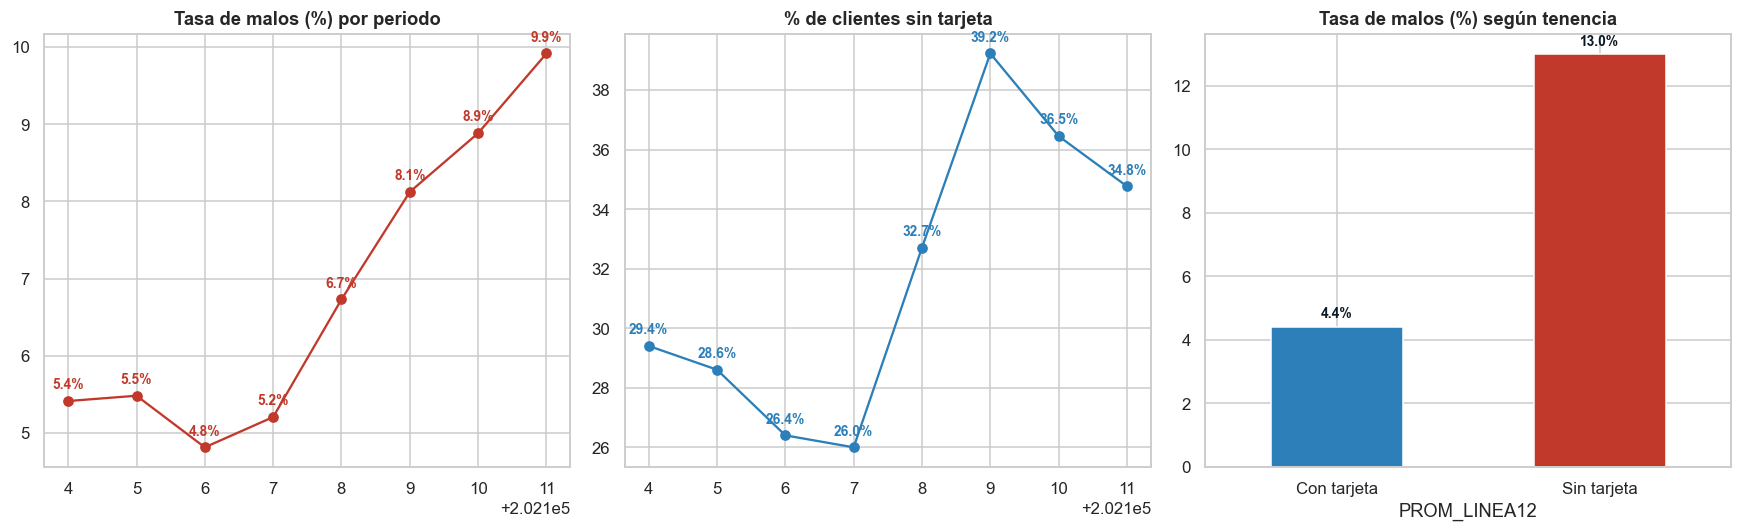

Tasa de malos según tenencia de tarjeta (el faltante ES la señal):


,size,mean
PROM_LINEA12,,
con tarjeta,87601,0.0442
sin tarjeta,42583,0.1298


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

por_periodo = df.groupby("PERIODO").bad.agg(["size", "mean"])
(por_periodo["mean"] * 100).plot(ax=ax[0], marker="o", color="#c0392b")
ax[0].set_title("Tasa de malos (%) por periodo"); ax[0].set_xlabel("")
linea = ax[0].lines[0]
for x, y in zip(linea.get_xdata(), linea.get_ydata()):
    ax[0].annotate(
        f"{y:.1f}%",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="#c0392b"
    )



# Faltantes estructurales: "sin dato" en tarjeta significa "no tiene tarjeta"
sin_tarjeta = df.PROM_LINEA12.isna()
(df.groupby("PERIODO").PROM_LINEA12.apply(lambda s: s.isna().mean()) * 100).plot(
    ax=ax[1], marker="o", color="#2c7fb8")
ax[1].set_title("% de clientes sin tarjeta"); ax[1].set_xlabel("")
linea = ax[1].lines[0]
for x, y in zip(linea.get_xdata(), linea.get_ydata()):
    ax[1].annotate(
        f"{y:.1f}%",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="#2c7fb8"
    )



df.groupby(sin_tarjeta).bad.mean().mul(100).plot.bar(ax=ax[2], color=["#2c7fb8", "#c0392b"])
ax[2].set_xticklabels(["Con tarjeta", "Sin tarjeta"], rotation=0)
ax[2].set_title("Tasa de malos (%) según tenencia")
for p in ax[2].patches:
  height = p.get_height()
  ax[2].annotate(
      f'{height:.1f}%',
      (p.get_x() + p.get_width() / 2., height),
      ha='center',
      va='bottom',
      xytext=(0, 4),  # Desplazamiento en puntos
      textcoords='offset points',
      fontsize=9,
      fontweight='bold',
      color="#0a1923",
  )


plt.tight_layout(); plt.show()


print("Tasa de malos según tenencia de tarjeta (el faltante ES la señal):")
display(df.groupby(sin_tarjeta).bad.agg(["size", "mean"]).rename(index={True: "sin tarjeta", False: "con tarjeta"}))

### 5.2 Valores atípicos

In [10]:
nunq = S.select_dtypes(include=[np.number]).nunique()
dom = S.select_dtypes(include=[np.number]).apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
print("Flags 1/vacío (un solo valor no nulo; el vacío equivale a 0):", nunq[nunq <= 1].index.tolist())
print("Casi constantes (>98% en un solo valor):", dom[dom > 0.98].index.tolist())
ext = S.select_dtypes(include=[np.number]).describe(percentiles=[.99]).T[["min", "99%", "max"]]
ext["ratio_max/p99"] = ext["max"] / ext["99%"].replace(0, np.nan)
display(ext.sort_values("ratio_max/p99", ascending=False).head(6))

Flags 1/vacío (un solo valor no nulo; el vacío equivale a 0): ['MARCA_HIP6', 'MARCA_HIP12', 'MARCA_HIP3']
Casi constantes (>98% en un solo valor): ['MAX_ATRASO3']


,min,99%,max,ratio_max/p99
MAX_GARAN_SALDO6,0.0000,30.5384,"12,000,000.0000","392,947.9022"
MAX_GARAN_SALDO12,0.0000,52.4171,"12,000,000.0000","228,932.7329"
MAX_GARAN_SALDO3,0.0000,24.7361,"5,163,611.0000","208,748.2683"
MAX_INT_SALDO6,0.0000,0.3406,"27,410.7500","80,487.2736"
MAX_INT_SALDO12,0.0000,0.5965,"27,410.7500","45,954.2256"
GARAN_SALDO,0.0000,22.0000,"488,515.4000","22,205.2455"


Hay colas extremas en ratios (p. ej. `GARAN_SALDO` (ratio garantias), `INT_SALDO`(ratio intereses): máximos miles de veces el p99). El **binning óptimo** (WoE) y los **árboles** son robustos a outliers, por lo que no se winsoriza: se evita alterar la información original y se simplifica la implementación.

### 5.3 El target

,clientes,malos,tasa_malos
PERIODO,,,
202104,10177,551,0.0541
202105,13624,747,0.0548
202106,11383,548,0.0481
202107,14174,738,0.0521
202108,19152,1289,0.0673
202109,21370,1736,0.0812
202110,20147,1790,0.0888
202111,20157,1999,0.0992


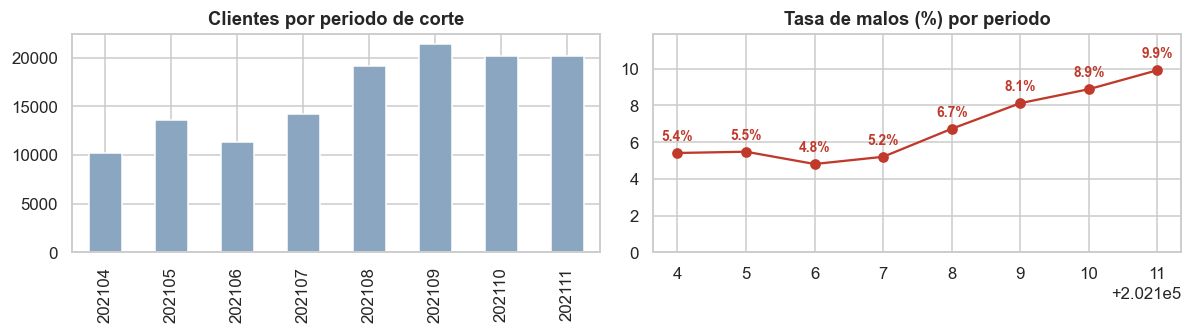

In [11]:
per = S.groupby("PERIODO").agg(clientes=("bad", "size"), malos=("bad", "sum"), tasa_malos=("bad", "mean"))
display(per)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
per.clientes.plot.bar(ax=ax[0], color="#8aa6c1", title="Clientes por periodo de corte"); ax[0].set_xlabel("")
(per.tasa_malos*100).plot(ax=ax[1], marker="o", color="#c0392b", title="Tasa de malos (%) por periodo"); ax[1].set_xlabel("")

# Extraemos las coordenadas exactas (X, Y) que Matplotlib dibujó
linea = ax[1].lines[0]
for x, y in zip(linea.get_xdata(), linea.get_ydata()):
    ax[1].annotate(
        f"{y:.1f}%",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="#c0392b"
    )

# Ajustamos el límite superior para que no se corte la etiqueta más alta
ax[1].set_ylim(0, (per.tasa_malos*100).max() * 1.2)
plt.tight_layout()

plt.tight_layout(); plt.show()

### 5.4 Valores categóricos

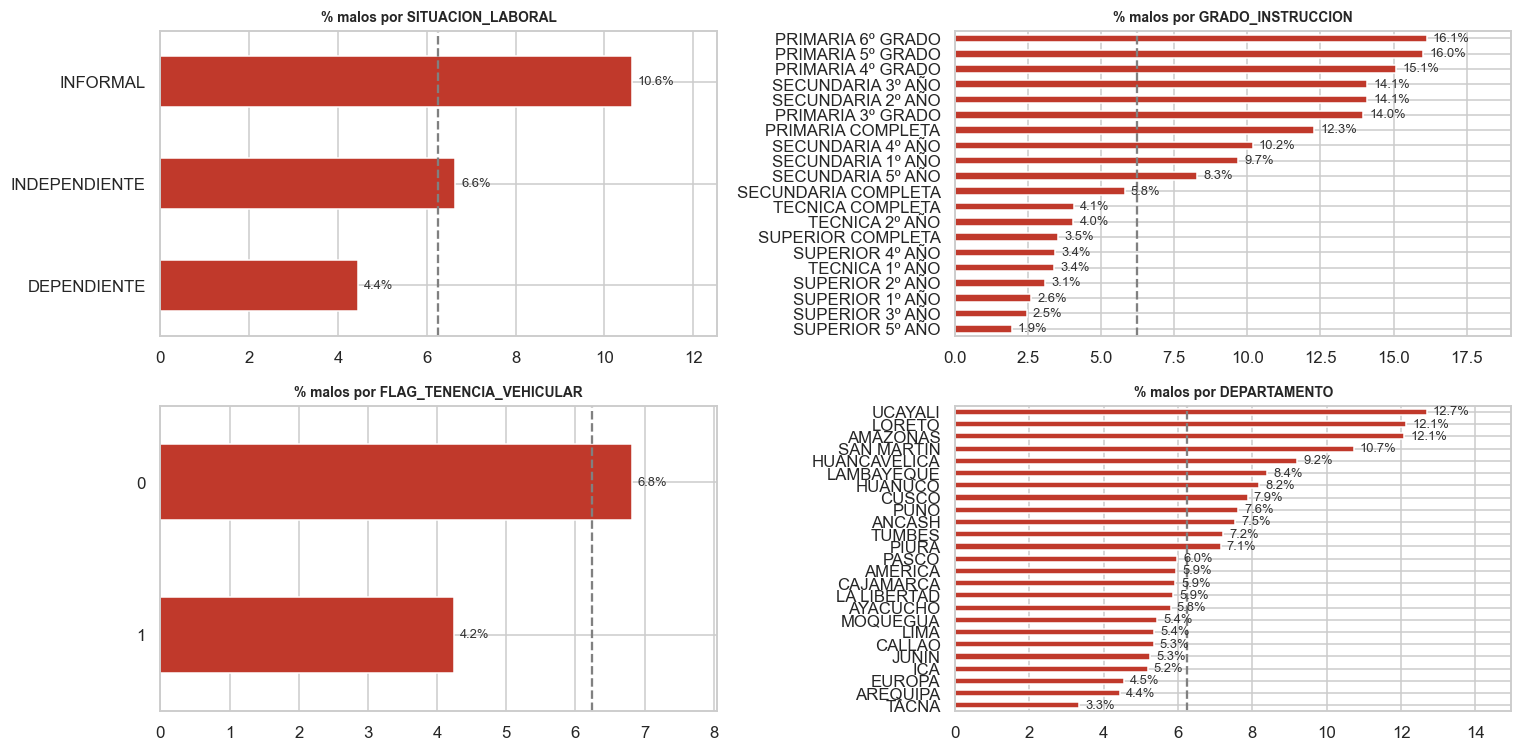

         mean   size
GENERO              
F      0.0554  36621
M      0.0722  26234


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))

# Usa axes.flat para recorrer los 4 subgráficos uno por uno
for ax, v in zip(axes.flat, ["SITUACION_LABORAL", "GRADO_INSTRUCCION", "FLAG_TENENCIA_VEHICULAR", "DEPARTAMENTO"]):
    t = tr.groupby(v).bad.agg(["mean", "size"])
    t = t[t["size"] >= 100].sort_values("mean")
    
    (t["mean"] * 100).plot.barh(ax=ax, color="#c0392b")
    
    # Agregar el valor porcentual a cada barra
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=4, fontsize=8.5, color="#333333")
    
    # Dar espacio extra a la derecha para que el texto no se corte
    ax.set_xlim(0, (t["mean"].max() * 100) * 1.18)
    
    ax.set_title(f"% malos por {v}", fontsize=9)
    ax.set_ylabel("")
    ax.axvline(tr.bad.mean() * 100, ls="--", color="gray")

plt.tight_layout()
plt.show()

ref = tr.groupby("GENERO").bad.agg(["mean", "size"])
print(ref)


`GENERO`, `ESTADO_CIVIL` y la ubicación (`DEPARTAMENTO/PROVINCIA/DISTRITO`) **tienen señal**, pero se **excluyen** del modelo: atributos protegidos/proxies geográficos que elevan el riesgo de discriminación indirecta y de conducta de mercado. En la sección 10 se cuantifica cuánto poder predictivo se resigna al excluirlas y se monitorea el impacto desigual de la decisión.

### 5.5 Distribución de las variables numéricas

Una representante por dimensión de riesgo. Lo que interesa no es la media sino la **forma**: asimetría, colas y si la distribución de los malos se desplaza respecto a la de los buenos. Las colas se recortan al percentil 99.5 solo para el gráfico; el modelo recibe los valores originales.

,count,%missing,mean,1%,50%,99%,max,max/p99,asimetría
CONTAR_COMP,"62,856.0000",0.0000,9.9840,0.0000,12.0000,12.0000,12.0000,1.0000,-1.5430
D12_MAXD,"61,577.0000",0.0200,0.6520,0.0000,0.7280,1.0000,1.0000,1.0000,-0.6340
MAX_LINEA12,"43,137.0000",0.3140,"15,795.2020",300.0000,"4,798.8600","153,682.7290","587,317.7000",3.8220,4.8420
INT_SALDO,"51,550.0000",0.1800,0.0300,0.0000,0.0150,0.1250,107.8860,864.4770,113.0270
MESES_ANT_RCC,"62,856.0000",0.0000,81.6130,3.0000,103.0000,116.0000,116.0000,1.0000,-0.7900
EDAD,"62,855.0000",0.0000,37.2500,21.0000,35.0000,70.0000,78.0000,1.1140,0.8500


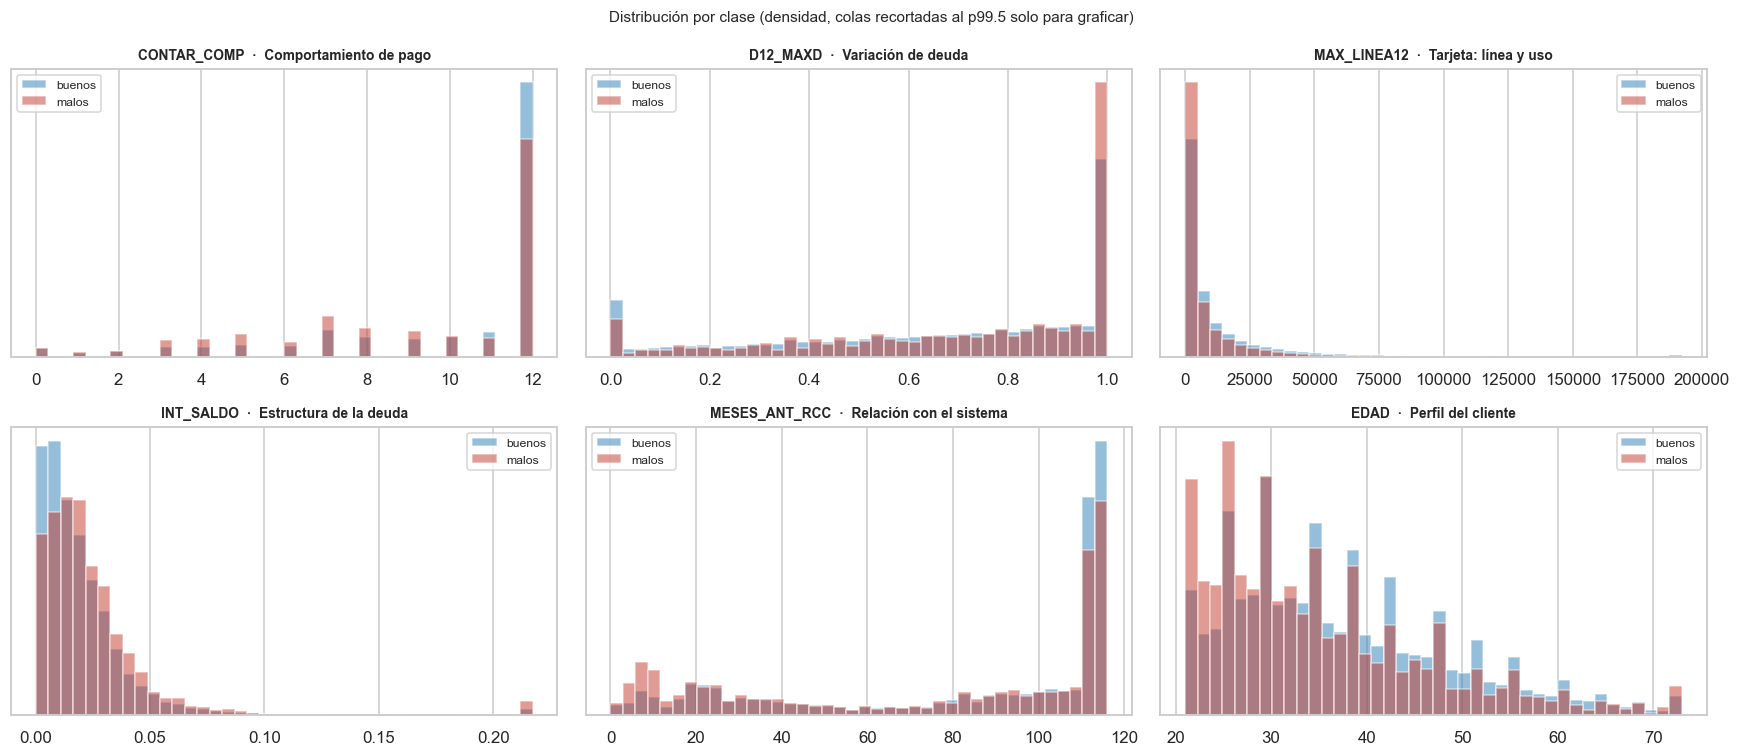

In [13]:
REPRESENTANTES = {"Comportamiento de pago":  "CONTAR_COMP",
                  "Variación de deuda":      "D12_MAXD",
                  "Tarjeta: línea y uso":    "MAX_LINEA12",
                  "Estructura de la deuda":  "INT_SALDO",
                  "Relación con el sistema": "MESES_ANT_RCC",
                  "Perfil del cliente":      "EDAD"}
REP = list(REPRESENTANTES.values())

desc = tr[REP].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["%missing"] = tr[REP].isna().mean()
desc["asimetría"] = tr[REP].skew()
desc["max/p99"] = desc["max"] / desc["99%"].replace(0, np.nan)
display(desc[["count", "%missing", "mean", "1%", "50%", "99%", "max", "max/p99", "asimetría"]].round(3))

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, (fam, v) in zip(axes.flat, REPRESENTANTES.items()):
    x = tr[v]; lo, hi = x.quantile(.005), x.quantile(.995)
    for etiqueta, grupo, color in (("buenos", 0, "#2c7fb8"), ("malos", 1, "#c0392b")):
        ax.hist(x[tr.bad == grupo].clip(lo, hi).dropna(), bins=40, density=True, alpha=.5, color=color, label=etiqueta)
    ax.set_title(f"{v}  ·  {fam}", fontsize=9); ax.legend(fontsize=8); ax.set_yticks([])
plt.suptitle("Distribución por clase (densidad, colas recortadas al p99.5 solo para graficar)", fontsize=10)
plt.tight_layout(); plt.show()

**Lectura.** Las distribuciones son asimétricas y con colas largas en casi todas las variables de monto y ratio: `max/p99` en el orden de decenas o centenas confirma que hay valores extremos que una media o una desviación estándar no describen. Entre buenos y malos las densidades se **desplazan** pero se **superponen** mucho: ninguna variable separa por sí sola, que es lo mismo que decía el control de fuga de la sección 3. Esa superposición es la razón de fondo por la que el modelo necesita combinar varias dimensiones y por la que el Gini alcanzable con información de buró es moderado.

### 5.6 Relación con el target antes de transformar

La tasa de malos por decil de cada variable muestra la **forma** de la relación (monótona, en U, plana) y dónde queda el faltante respecto al resto. Es la verificación visual previa al binning: si aquí la relación es monótona, el binning monotónico de la sección 6 no fuerza nada; si no lo fuera, habría que decidirlo con negocio.

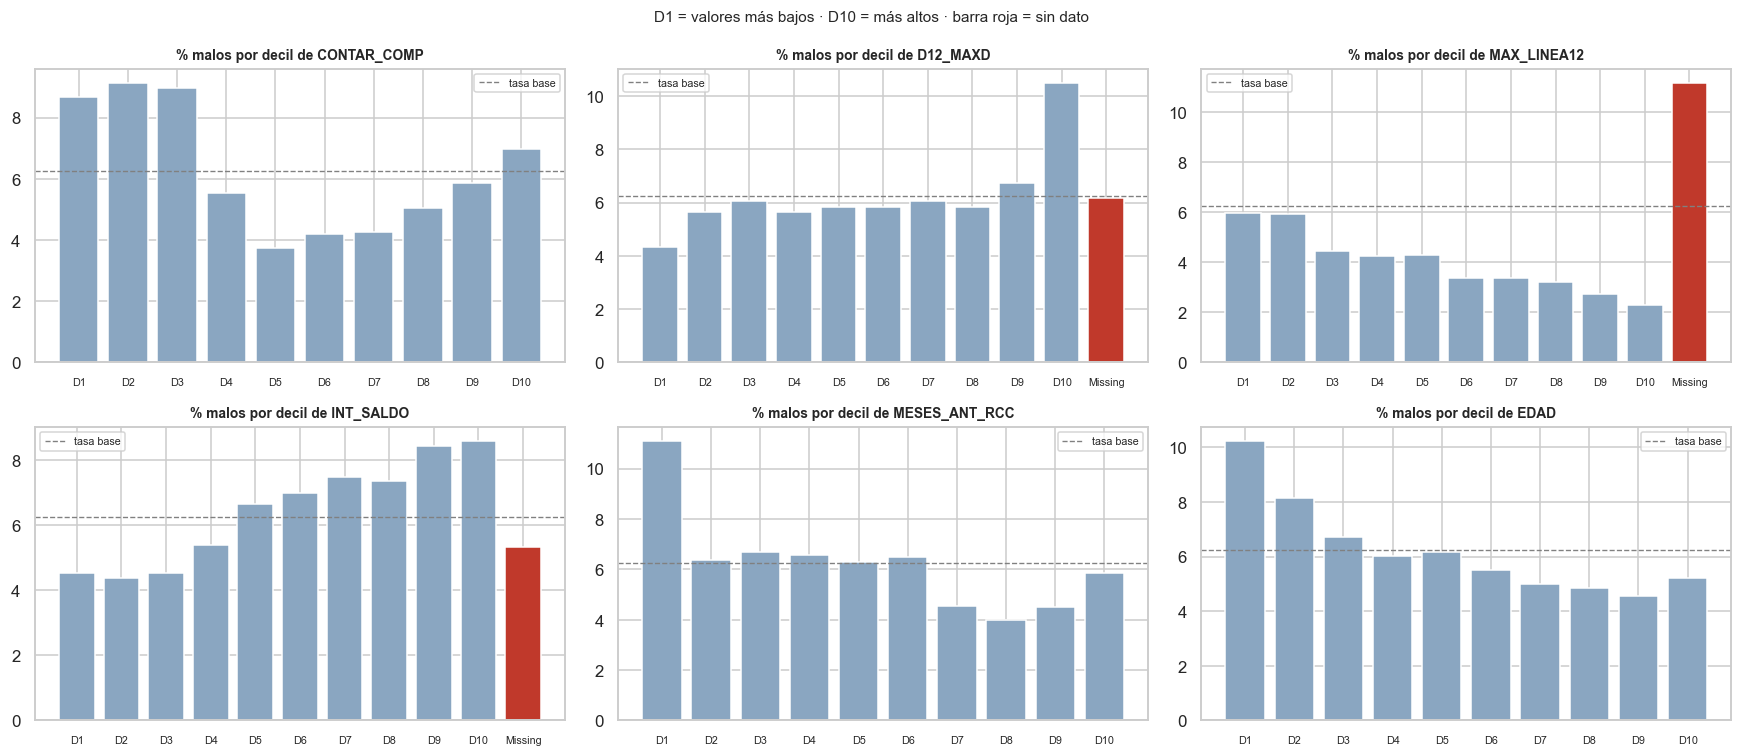

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
orden = [f"D{i}" for i in range(1, 11)] + ["Missing"]
for ax, (fam, v) in zip(axes.flat, REPRESENTANTES.items()):
    d = tr[[v, "bad"]].copy()
    con = d[v].notna()
    d.loc[con, "tramo"] = pd.qcut(d.loc[con, v].rank(method="first"), 10, labels=orden[:10]).astype(str)
    d.loc[~con, "tramo"] = "Missing"
    t = d.groupby("tramo").bad.agg(["mean", "size"]).reindex(orden).dropna()
    t = t[t["size"] >= 100]
    ax.bar(t.index, t["mean"] * 100, color=["#c0392b" if k == "Missing" else "#8aa6c1" for k in t.index])
    ax.axhline(tr.bad.mean() * 100, ls="--", color="gray", lw=.9, label="tasa base")
    ax.set_title(f"% malos por decil de {v}", fontsize=9); ax.tick_params(axis="x", labelsize=7); ax.legend(fontsize=7)
plt.suptitle("D1 = valores más bajos · D10 = más altos · barra roja = sin dato", fontsize=10)
plt.tight_layout(); plt.show()

**Lectura.** La mayoría de las relaciones es monótona en la dirección que dicta el negocio: más línea, más antigüedad en el sistema y más meses en Normal bajan la mora; más interés generado sobre el saldo la sube. El faltante se comporta como un tramo más, con su propia tasa, y en el caso de las variables de tarjeta es el tramo **más riesgoso**: imputarlo con la mediana lo habría mezclado con clientes de riesgo medio. `EDAD` es la excepción habitual: la mora es alta en los jóvenes y baja con la edad, también de forma monótona en esta base, así que no hace falta una forma en U.

### 5.7 Correlación entre variables numéricas

Dos preguntas. Primero, cuánta redundancia hay en la base: 149 candidatas no son 149 señales. Segundo, dónde está esa redundancia: la hipótesis es que las ventanas de 3, 6 y 12 meses de una misma señal se mueven juntas. Se usa Spearman porque es robusto a las colas que mostró 5.5.

Pares con |rho| > 0.90: 160  |  > 0.70: 380  de 20,736 pares posibles
Variables que tienen al menos un par con |rho| > 0.90: 101 de 144


,,|rho| Spearman
PROM_UTIL_EFEC3,MAX_UTIL_EFEC3,0.9996
PROM_UTIL_EFEC6,MAX_UTIL_EFEC6,0.9991
Max_AumMORA,MAX_CALIF12,0.9989
PROM_LINEA12,LINT_PROM12,0.9981
PROM_UTIL_EFEC12,MAX_UTIL_EFEC12,0.9980
MAX_DMES_DTOTAL3,PROM_DMES_DTOTAL3,0.9967
PROM_UTIL_EFEC3,RATIOS_PROM_EFEC_DEUDA3,0.9953
MAX_UTIL_EFEC3,RATIOS_PROM_EFEC_DEUDA3,0.9948
PROM_UTIL_EFEC6,RATIOS_PROM_EFEC_DEUDA6,0.9940
MAX_DMES_DTOTAL6,PROM_DMES_DTOTAL6,0.9939


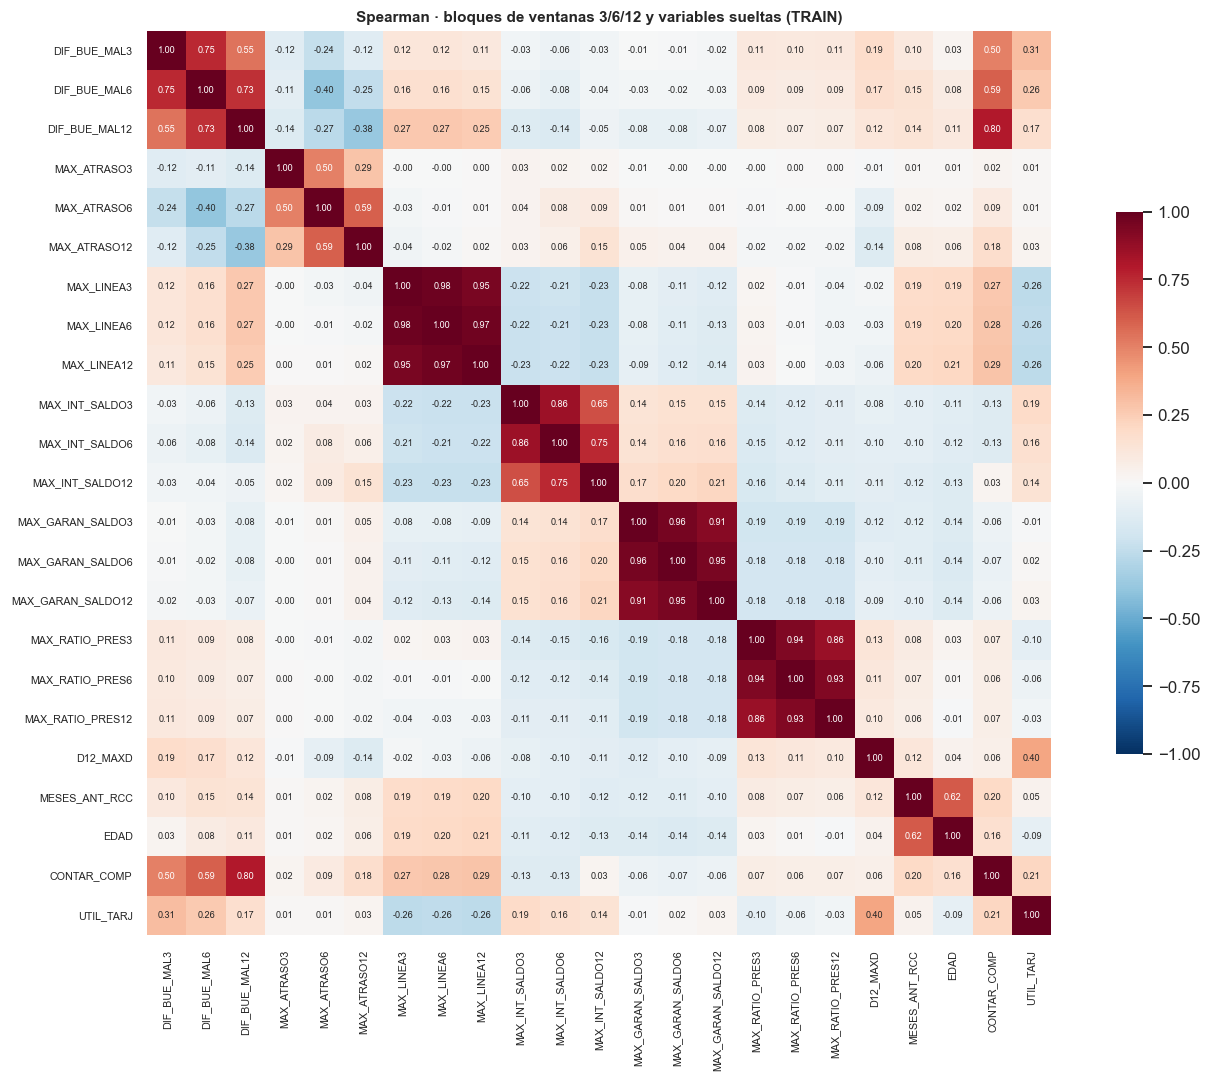

In [15]:
# (a) Redundancia global entre todas las numéricas, sobre una muestra de TRAIN para que sea rápido
muestra_corr = tr[NUMERICAS].sample(min(20_000, len(tr)), random_state=SEED)
muestra_corr = muestra_corr.loc[:, muestra_corr.nunique() > 1]
C = muestra_corr.corr(method="spearman").abs()
tri = C.where(np.triu(np.ones(C.shape, dtype=bool), k=1))
pares = tri.stack().sort_values(ascending=False)
print(f"Pares con |rho| > 0.90: {(pares > .90).sum():,}  |  > 0.70: {(pares > .70).sum():,}  "
      f"de {len(pares):,} pares posibles")
print(f"Variables que tienen al menos un par con |rho| > 0.90: "
      f"{len(set(pares[pares > .90].index.get_level_values(0)) | set(pares[pares > .90].index.get_level_values(1)))} de {C.shape[0]}")
display(pares.head(12).to_frame("|rho| Spearman"))

# (b) Dónde está la redundancia: bloques de ventanas 3/6/12 de la misma señal
import re
bloques = ["DIF_BUE_MAL", "MAX_ATRASO", "MAX_LINEA", "MAX_INT_SALDO", "MAX_GARAN_SALDO", "MAX_RATIO_PRES"]
cols_bloque = [c for b in bloques for c in (f"{b}3", f"{b}6", f"{b}12") if c in tr.columns]
cols_bloque += [v for v in ["D12_MAXD", "MESES_ANT_RCC", "EDAD", "CONTAR_COMP", "UTIL_TARJ"] if v in tr.columns]
Cb = tr[cols_bloque].corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(Cb, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 6},
            square=True, cbar_kws={"shrink": .6}, ax=ax)
ax.set_title("Spearman · bloques de ventanas 3/6/12 y variables sueltas (TRAIN)", fontsize=10)
ax.tick_params(labelsize=7); plt.tight_layout(); plt.show()

**Lectura.** La redundancia es alta y está localizada: dentro de cada bloque de ventanas la correlación supera 0.9, y entre bloques distintos baja a valores moderados o cercanos a cero. Es la justificación empírica de la poda por colinealidad de la sección 6 (entre pares con $|\rho|>0.70$ sobre el WoE se conserva la de mayor IV): sin ella el forward llenaría el modelo con tres versiones de la misma señal, y los coeficientes repartirían el efecto entre ellas de forma inestable. También explica por qué el experimento de reglas descartó R2: fijar *a priori* la ventana corta no agrega información, solo elige una de tres columnas casi idénticas.

### 5.8 Asociación entre categóricas: V de Cramér

La correlación de Pearson o Spearman no aplica a categóricas. La **V de Cramér** (con la corrección de sesgo de Bergsma) mide la asociación entre dos variables nominales en escala 0–1 a partir de la tabla de contingencia. Se incluyen las variables excluidas por política para responder una pregunta concreta: ¿las que sí entran al modelo son *proxies* de las que se excluyen?

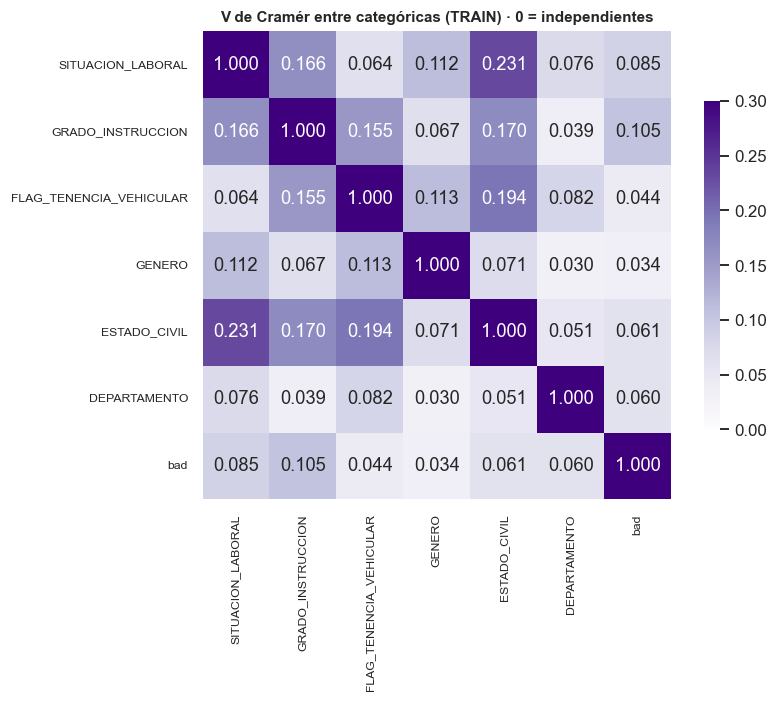

Asociación de cada categórica con el target y con las variables excluidas por política:


,bad,GENERO,ESTADO_CIVIL,DEPARTAMENTO
SITUACION_LABORAL,0.0850,0.1120,0.2310,0.0760
GRADO_INSTRUCCION,0.1050,0.0670,0.1700,0.0390
FLAG_TENENCIA_VEHICULAR,0.0440,0.1130,0.1940,0.0820


In [16]:
from scipy.stats import chi2_contingency

def cramers_v(a, b):
    """V de Cramér con corrección de sesgo (Bergsma 2013). Devuelve 0 cuando no hay asociación."""
    tabla = pd.crosstab(a, b)
    if tabla.shape[0] < 2 or tabla.shape[1] < 2:
        return 0.0
    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum(); r, k = tabla.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_, k_ = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / max(1e-12, min(k_ - 1, r_ - 1))))

CATS_EDA = ["SITUACION_LABORAL", "GRADO_INSTRUCCION", "FLAG_TENENCIA_VEHICULAR",   # entran como candidatas
            "GENERO", "ESTADO_CIVIL", "DEPARTAMENTO",                               # excluidas por política
            "bad"]                                                                  # el target
d_cat = tr[CATS_EDA].astype(str)
V = pd.DataFrame([[cramers_v(d_cat[a], d_cat[b]) for b in CATS_EDA] for a in CATS_EDA], index=CATS_EDA, columns=CATS_EDA)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(V, cmap="Purples", vmin=0, vmax=max(.3, V.values[~np.eye(len(V), dtype=bool)].max()), annot=True, fmt=".3f",
            square=True, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("V de Cramér entre categóricas (TRAIN) · 0 = independientes", fontsize=10)
ax.tick_params(labelsize=8); plt.tight_layout(); plt.show()

print("Asociación de cada categórica con el target y con las variables excluidas por política:")
display(V.loc[["SITUACION_LABORAL", "GRADO_INSTRUCCION", "FLAG_TENENCIA_VEHICULAR"],
              ["bad", "GENERO", "ESTADO_CIVIL", "DEPARTAMENTO"]].round(3))

**Lectura.** Las asociaciones con el target son modestas (V por debajo de 0.15 es lo habitual en riesgo de crédito con una tasa base del 6%), coherente con que ninguna variable discrimina sola. Lo que importa es la columna de las variables excluidas: la V entre `SITUACION_LABORAL` o `GRADO_INSTRUCCION` y `GENERO`/`ESTADO_CIVIL`/`DEPARTAMENTO` es baja, es decir, **las categóricas que entran al modelo no reconstruyen a las que se excluyen**. Eso no cierra el tema de equidad —un proxy puede ser una combinación de numéricas, y por eso la sección 10 mide el costo de la exclusión y la tabla de pendientes pide medir obs/pred por grupo—, pero descarta el proxy más obvio.

**Lectura del EDA.**

* **Target**: 7.2% de malos en toda la base (6.2% en la ventana de desarrollo, 9.4% fuera de tiempo), con tendencia creciente → validar siempre OOT y monitorear deriva/calibración.
* **Faltantes** estructurales e informativos → categoría propia, no imputación. Caso de clientes sin tarjeta.
* **Señal** repartida en muchas variables; no hay leakage.
* **Exclusiones**: `GENERO`, `ESTADO_CIVIL`, `DEPARTAMENTO/PROVINCIA/DISTRITO`, `serie`, `PERIODO` (proxies de variables que si discriminan).


## 6. WoE, Information Value y selección de variables

### Por qué hacer binning WoE (weight of evidence)

Cada variable se discretiza en tramos con **binning óptimo monotónico** y cada tramo se reemplaza por su *Weight of Evidence*:

$$WoE_i = \ln\left(\frac{\%\text{buenos en el tramo } i}{\%\text{malos en el tramo } i}\right)$$

Tres consecuencias prácticas, que son las que justifican no imputar ni tratar outliers (sección 2):

1. **El faltante es un tramo más**, con su WoE estimado sobre la tasa de malos real de ese grupo.
2. **Los valores extremos caen en el último tramo** y pesan igual que cualquier otro valor de ese tramo.
3. **La relación queda monotónica por construcción**, así que el coeficiente esperado en la regresión se conoce de antemano: con esta convención WoE alto = menos riesgo, luego el coeficiente debe ser **negativo**. Eso convierte el signo en un chequeo objetivo y no en una opinión.

El **IV** (information values) resume el poder de la variable: $IV = \sum_i (\%buenos_i - \%malos_i) \cdot WoE_i$.

In [17]:
# Binning ajustado SOLO con TRAIN
bins, filas_iv = {}, []
for v in CANDIDATAS:
    dtype = "categorical" if v in CATEGORICAS else "numerical"
    extra = dict(monotonic_trend="auto_asc_desc") if dtype == "numerical" else dict(cat_cutoff=0.03)
    ob = OptimalBinning(name=v, dtype=dtype, max_n_bins=10, min_bin_size=0.05, **extra)
    x = tr[v].values if dtype == "numerical" else tr[v].astype(object).where(tr[v].notna(), None).values
    try:
        ob.fit(x, tr.bad.values)
    except Exception:
        continue
    if ob.status not in ("OPTIMAL", "FEASIBLE"):
        continue
    ob.binning_table.build()                       # necesario antes de leer .iv
    bins[v] = ob
    filas_iv.append({"variable": v, "tipo": dtype, "IV": float(ob.binning_table.iv),
                     "pct_faltante": float(tr[v].isna().mean())})

IV = pd.DataFrame(filas_iv).set_index("variable").sort_values("IV", ascending=False)
IV["fuerza"] = pd.cut(IV.IV, [-1, .02, .1, .3, .5, 99],
                      labels=["inútil", "débil", "media", "fuerte", "sospechosa"])
print(f"{len(bins)} de {len(CANDIDATAS)} variables con binning válido")
display(IV.head(10))
display(IV.fuerza.value_counts().to_frame("variables"))

149 de 149 variables con binning válido


,tipo,IV,pct_faltante,fuerza
variable,,,,
MAX_LINEA12,numerical,0.3511,0.3137,fuerte
LINT_PROM12,numerical,0.3503,0.3138,fuerte
PROM_LINEA12,numerical,0.3497,0.3137,fuerte
MAX_LINEA6,numerical,0.3409,0.3232,fuerte
PROM_LINEA6,numerical,0.3406,0.3232,fuerte
Max_DismKT,numerical,0.3401,0.0000,fuerte
PROM_LINEA3,numerical,0.3316,0.3286,fuerte
MAX_LINEA3,numerical,0.3301,0.3286,fuerte
LINEA_BASE,numerical,0.3237,0.3326,fuerte


,variables
fuerza,
débil,50
inútil,42
media,35
fuerte,22
sospechosa,0


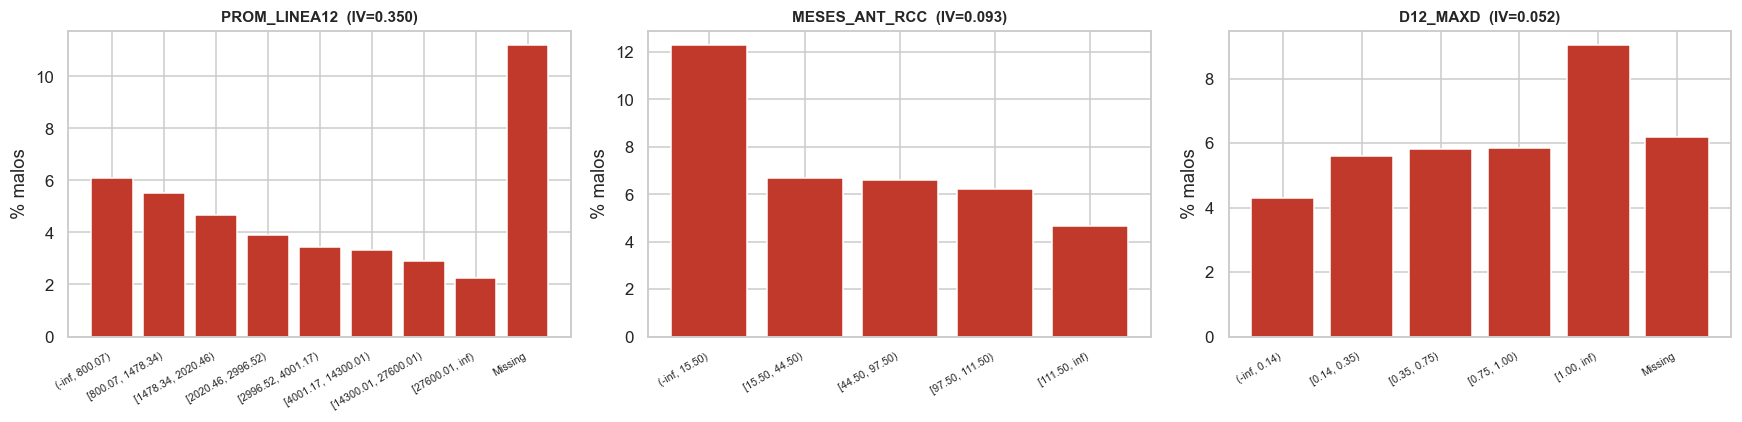

El tramo 'Missing' aparece como una barra más, con su propia tasa de malos.


In [18]:
def woe(d, variables):
    """Aplica a un DataFrame el binning ya ajustado y devuelve la matriz WoE."""
    out = {}
    for v in variables:
        x = d[v].values if bins[v].dtype == "numerical" else d[v].astype(object).where(d[v].notna(), None).values
        out[v] = bins[v].transform(x, metric="woe", metric_missing="empirical", metric_special="empirical")
    return pd.DataFrame(out, index=d.index)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, v in zip(axes, ["PROM_LINEA12", "MESES_ANT_RCC", "D12_MAXD"]):
    t = bins[v].binning_table.build()
    t = t[(t.index != "Totals") & (t["Count"] > 0)]
    ax.bar(range(len(t)), t["Event rate"] * 100, color="#c0392b")
    ax.set_xticks(range(len(t))); ax.set_xticklabels(t["Bin"].astype(str), rotation=30, ha="right", fontsize=7)
    ax.set_title(f"{v}  (IV={IV.loc[v, 'IV']:.3f})", fontsize=10); ax.set_ylabel("% malos")
plt.tight_layout(); plt.show()
print("El tramo 'Missing' aparece como una barra más, con su propia tasa de malos.")

### Filtros estadísticos

1. **IV entre 0.02 y 0.50.** Por debajo no aporta; por encima conviene sospechar de fuga.
2. **PSI del WoE entre TRAIN y OOT < 0.25.** Una variable inestable en el tiempo es un riesgo de modelo, por buena que sea hoy. Este filtro usa solo la **distribución de las variables** en OOT, nunca su target: es la misma información que existiría en producción al momento de puntuar. Lo que no se usa de OOT para ninguna decisión es el **target** (sección 6 y 10). Medido solo dentro de desarrollo, este filtro dejaría pasar `DMES_DTOTAL`, cuyo quiebre (PSI ≈ 1.5) ocurre recién en octubre.
3. **Colinealidad:** entre variables con $|\rho| > 0.70$ sobre el WoE se conserva la de mayor IV. Las ventanas de 3, 6 y 12 meses de una misma señal están correlacionadas por encima de 0.95, así que sin este filtro el modelo se llenaría de duplicados.

In [19]:
cand = IV[(IV.IV >= 0.02) & (IV.IV <= 0.50)].index.tolist()
W_tr, W_oot = woe(tr, cand), woe(oot, cand)
y_tr = tr.bad.values

# PSI sobre WoE: los cortes son los propios valores discretos del WoE
def psi_woe(a, b):
    u = np.unique(a)
    return 0.0 if len(u) < 2 else psi(a, b, cortes=np.r_[-np.inf, u[:-1] + np.diff(u) / 2, np.inf])

estabilidad = pd.Series({v: psi_woe(W_tr[v], W_oot[v]) for v in cand}).sort_values(ascending=False)
estables = [v for v in cand if estabilidad[v] < 0.25]
print(f"IV válido: {len(cand)}  ->  estables (PSI < 0.25): {len(estables)}")
print(f"Descartadas por inestables: {sorted(set(cand) - set(estables))}")
display(estabilidad.head(4).to_frame("PSI TRAIN->OOT"))

# Poda de colinealidad: se recorre por IV descendente y se conserva lo no redundante
sin_colinealidad = []
for v in IV.loc[estables].sort_values("IV", ascending=False).index:
    if all(abs(W_tr[v].corr(W_tr[k])) < 0.70 for k in sin_colinealidad):
        sin_colinealidad.append(v)
print(f"\nTras la poda de colinealidad: {len(sin_colinealidad)} variables")

IV válido: 107  ->  estables (PSI < 0.25): 106
Descartadas por inestables: ['DMES_DTOTAL']


,PSI TRAIN->OOT
DMES_DTOTAL,1.5156
MESES_ANT_RCC,0.0688
CONTAR_COMP,0.0353
DIF_BUE_MAL12,0.0257



Tras la poda de colinealidad: 31 variables


### Qué hizo la poda de colinealidad

El bloque anterior imprime cuántas variables quedan; este muestra **cuáles salieron y por culpa de quién**, y cómo se ve la matriz de correlación del WoE antes y después. Es la evidencia de que la poda eliminó duplicados y no señales distintas.

75 eliminadas · 31 conservadas
Misma raíz (ventanas 3/6/12 de la misma señal): 29% de las eliminaciones
Variables que más absorbieron: {'MAX_LINEA12': 33, 'MAX_DMES_DTOTAL12': 7, 'MAX_GARAN_SALDO6': 6, 'MAX_ENT_REP12': 5, 'MAX_KTOT_M12': 3}


,eliminada,IV,redundante con,IV conservada,|rho| WoE
0,LINT_PROM12,0.3500,MAX_LINEA12,0.3510,0.9890
1,PROM_LINEA12,0.3500,MAX_LINEA12,0.3510,0.9890
2,MAX_LINEA6,0.3410,MAX_LINEA12,0.3510,0.9790
3,PROM_LINEA6,0.3410,MAX_LINEA12,0.3510,0.9750
4,Max_DismKT,0.3400,MAX_LINEA12,0.3510,0.8050
5,PROM_LINEA3,0.3320,MAX_LINEA12,0.3510,0.9650
6,MAX_LINEA3,0.3300,MAX_LINEA12,0.3510,0.9680
7,LINEA_BASE,0.3240,MAX_LINEA12,0.3510,0.9610
8,MAX_UTIL_COMP12,0.3140,MAX_LINEA12,0.3510,0.8790
9,PROM_UTIL_COMP12,0.3140,MAX_LINEA12,0.3510,0.8960


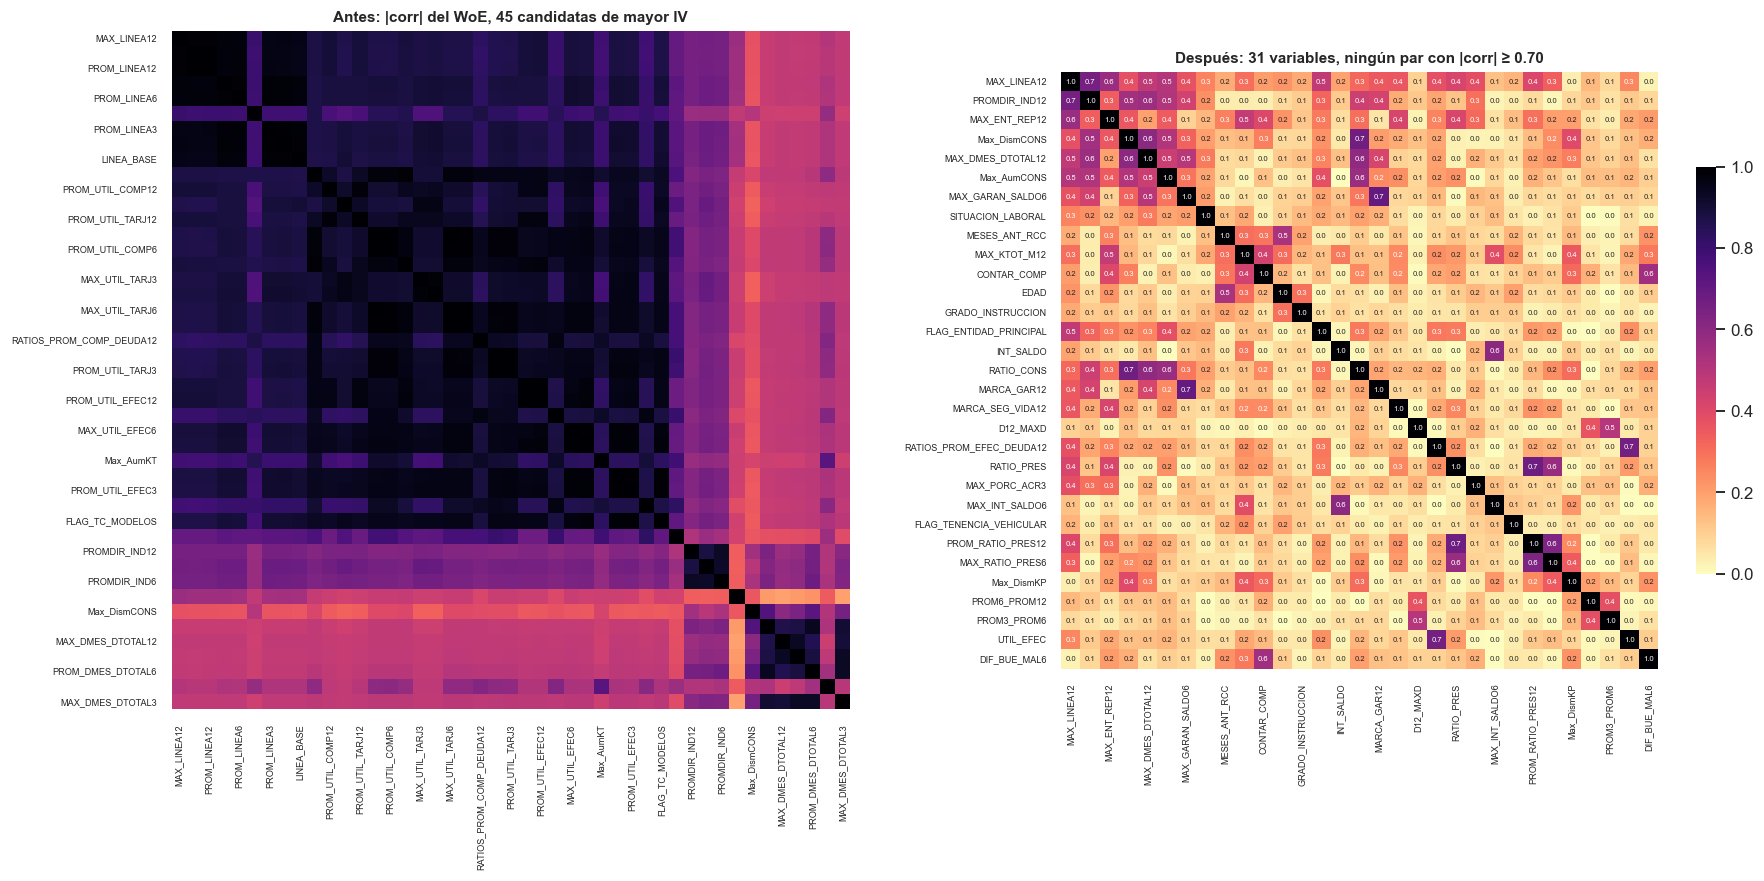

In [20]:
# Reconstrucción auditable de la poda: misma regla que arriba, registrando el par que eliminó a cada variable
orden_iv = IV.loc[estables].sort_values("IV", ascending=False).index.tolist()
C_woe = W_tr[orden_iv].corr().abs()
conservadas, eliminadas = [], []
for v in orden_iv:
    choque = [(k, C_woe.loc[v, k]) for k in conservadas if C_woe.loc[v, k] >= 0.70]
    if choque:
        k, r = max(choque, key=lambda t: t[1])
        eliminadas.append({"eliminada": v, "IV": IV.loc[v, "IV"], "redundante con": k, "IV conservada": IV.loc[k, "IV"], "|rho| WoE": r})
    else:
        conservadas.append(v)
assert conservadas == sin_colinealidad, "la reconstrucción debe coincidir con la poda de la celda anterior"

poda = pd.DataFrame(eliminadas)
print(f"{len(eliminadas)} eliminadas · {len(conservadas)} conservadas")
misma_raiz = lambda a, b: re.sub(r"(3|6|12)$", "", a) == re.sub(r"(3|6|12)$", "", b)   # ventanas 3/6/12 de la misma señal
print(f"Misma raíz (ventanas 3/6/12 de la misma señal): {np.mean([misma_raiz(a, b) for a, b in zip(poda.eliminada, poda['redundante con'])]):.0%} de las eliminaciones")
print("Variables que más absorbieron:", poda["redundante con"].value_counts().head(5).to_dict())
display(poda.sort_values("IV", ascending=False).head(15).round(3))

fig, axes = plt.subplots(1, 2, figsize=(17, 8))
top = orden_iv[:45]
sns.heatmap(W_tr[top].corr().abs(), cmap="magma_r", vmin=0, vmax=1, square=True, cbar=False, ax=axes[0])
axes[0].set_title(f"Antes: |corr| del WoE, {len(top)} candidatas de mayor IV", fontsize=10)
sns.heatmap(W_tr[sin_colinealidad].corr().abs(), cmap="magma_r", vmin=0, vmax=1, square=True,
            annot=True, fmt=".1f", annot_kws={"size": 5}, cbar_kws={"shrink": .6}, ax=axes[1])
axes[1].set_title(f"Después: {len(sin_colinealidad)} variables, ningún par con |corr| ≥ 0.70", fontsize=10)
for ax in axes: ax.tick_params(labelsize=6)
plt.tight_layout(); plt.show()

**Lectura.** La redundancia es **de familia más que de ventana**: una fracción de las eliminaciones es entre ventanas 3/6/12 de la misma raíz, pero la mayor parte ocurre entre variables distintas que miden lo mismo con otro nombre —línea máxima, línea promedio, línea base, utilización de tarjeta y de compras son todas versiones de "cuánta tarjeta tiene y usa", y `MAX_LINEA12` las absorbe a todas porque tiene el IV más alto del grupo. Los bloques oscuros de la matriz de la izquierda son esas familias; a la derecha no queda ningún par por encima de 0.70 y los valores típicos están entre 0.1 y 0.4. Es la condición que necesita el forward para que la contribución de cada variable sea atribuible y el VIF quede bajo.

### Reglas de negocio: cuáles sobreviven a la verificación

El indicador estadístico no sabe que esto es un modelo *early*, ni qué variables son defendibles ante un comité. Por eso se imponen reglas de negocio. Pero **una regla sin verificación es una opinión disfrazada de método**: las cinco que se evaluaron se contrastan contra los datos en el experimento de abajo, y **solo una sobrevive**.

| Regla | Qué hace | Tipo de justificación |
|---|---|---|
| **R1 · Cobertura ≥ 10%** | excluye variables con dato en menos del 10% de clientes | **operativa**: una variable así no es monitoreable en producción y su IV se estima sobre muy pocos casos |
| **R2 · Ventana corta por defecto** | la versión de 12 meses entra solo si su IV supera en 25% a la mejor de 3 o 6 meses | **de estabilidad** - se verifica abajo |
| **R3 · Tope por familia** | máximo de variables por dimensión de riesgo | a verificar |
| **R4 · Familias obligatorias** | forzar al menos una variable de pago, deuda y tarjeta | a verificar |
| **R5 · Excluir `INT_SALDO`** | saca la variable de rendimiento sobre saldo | **conceptual**, a verificar: ¿es la tasa que fija el banco o es comportamiento del cliente? |

#### Qué mide el experimento

La justificación habitual de R2 es que en mora temprana pesa el deterioro reciente, y **esa justificación no se sostiene**: la sección 3 mostró que el evento es casi independiente del atraso reciente. La alternativa era defenderla por estabilidad: dentro de una familia 3/6/12 los IV están casi empatados y las variables están correlacionadas por encima de 0.95, así que fijar una preferencia *a priori* evita que el empate lo rompa el azar de la muestra. El experimento pone a prueba esa segunda defensa: repite la selección sobre tres submuestras distintas de TRAIN y reporta cuántas variables comparten entre sí (Jaccard medio) junto al Gini en TEST (OOT no se usa para elegir reglas), de modo que se ve si la estabilidad se gana gratis o se paga.

#### Qué es `INT_SALDO` y por qué merece una celda propia

La bitácora la define como *ratio del rendimiento entre saldo*: el interés que genera el cliente sobre lo que debe, es decir, **la tasa efectiva que se le está cobrando**. Eso abre una objeción seria: si el banco fija precios según riesgo, esa tasa ya contiene la evaluación de riesgo previa del propio banco, y un modelo que la use aprende en parte la salida del modelo anterior (**circularidad**). Además, un repricing movería el score sin que el cliente haya cambiado. Esta cuestión sale dado que se tiene información del RCC, donde no tenemos saldos pero si se pueden hacer estimaciones de rendimiento / tasas.

Pero la misma variable captura algo que ninguna otra mide directamente: **cuánto interés genera realmente el cliente**, que depende de si revuelve el saldo, si paga el mínimo, si incurre en moras y comisiones. Eso es comportamiento, y es un predictor clásico de default. Las dos lecturas son compatibles y la pregunta es empírica: ¿cuánto de la variable es tarifa y cuánto es cliente? Si fuera tarifa, sería casi constante dentro de cada producto y la explicarían las variables de mezcla. Si es comportamiento, varía dentro del producto y discrimina aun controlando por utilización.

In [21]:
# ¿Qué captura INT_SALDO? Tarifa del banco (constante dentro del producto) o comportamiento del cliente.
v = "INT_SALDO"
x = tr[v]

mezcla = tr[["RATIO_CONS", "RATIO_PRES", "DOTROS_DTOTAL", "DMES_DTOTAL"]]
comportamiento = tr[["UTIL_TARJ", "UTIL_COMP", "D12_MAXD", "DIF_BUE_MAL12", "CONTAR_COMP", "Max_AumKT"]]

def varianza_explicada(X):
    d = pd.concat([x, X], axis=1).dropna()
    return sm.OLS(np.log1p(d[v].clip(lower=0)), sm.add_constant(d.drop(columns=v))).fit().rsquared

print(f"Cobertura {x.notna().mean():.0%} · IV {IV.loc[v, 'IV']:.4f} · PSI TRAIN->OOT {estabilidad[v]:.4f} · "
      f"Gini univariado {gini(tr.bad[x.notna()], x[x.notna()]):.3f}")
print(f"\nVarianza de log(INT_SALDO) explicada por la MEZCLA de productos  : {varianza_explicada(mezcla):.1%}")
print(f"Varianza explicada por las variables de COMPORTAMIENTO           : {varianza_explicada(comportamiento):.1%}")
print(f"Varianza explicada por ambas                                      : {varianza_explicada(mezcla.join(comportamiento)):.1%}")

print("\nCorrelación de Spearman con INT_SALDO:")
display(mezcla.join(comportamiento).corrwith(x, method="spearman").sort_values(key=abs, ascending=False)
        .round(3).to_frame("rho"))

# ¿Discrimina aun controlando por utilización? (solo clientes con tarjeta)
con_tc = tr[tr.PROM_LINEA12.notna() & x.notna()]
cuartil = pd.qcut(con_tc.UTIL_TARJ.rank(method="first"), 4, labels=["Q1 (baja)", "Q2", "Q3", "Q4 (alta)"])
print("Gini de INT_SALDO dentro de cada cuartil de utilización de tarjeta:")
display(con_tc.groupby(cuartil, observed=True).apply(lambda g: gini(g.bad, g[v]), include_groups=False)
        .round(3).to_frame("Gini"))
print("Mediana de INT_SALDO por periodo:", df.groupby("PERIODO")[v].median().round(4).to_dict())

Cobertura 82% · IV 0.0672 · PSI TRAIN->OOT 0.0050 · Gini univariado 0.144

Varianza de log(INT_SALDO) explicada por la MEZCLA de productos  : 0.8%
Varianza explicada por las variables de COMPORTAMIENTO           : 1.8%
Varianza explicada por ambas                                      : 7.9%

Correlación de Spearman con INT_SALDO:


C:\Users\Usuario\AppData\Local\Temp\ipykernel_21444\3062631876.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  return sm.OLS(np.log1p(d[v].clip(lower=0)), sm.add_constant(d.drop(columns=v))).fit().rsquared


,rho
UTIL_TARJ,0.2010
UTIL_COMP,0.1860
DOTROS_DTOTAL,-0.1500
CONTAR_COMP,-0.1300
DIF_BUE_MAL12,-0.1290
D12_MAXD,-0.1000
DMES_DTOTAL,0.0670
RATIO_CONS,0.0670
RATIO_PRES,-0.0640
Max_AumKT,-0.0620


Gini de INT_SALDO dentro de cada cuartil de utilización de tarjeta:


,Gini
UTIL_TARJ,
Q1 (baja),0.1000
Q2,0.1650
Q3,0.1020
Q4 (alta),0.0760


Mediana de INT_SALDO por periodo: {202104: 0.0144, 202105: 0.0154, 202106: 0.0143, 202107: 0.0135, 202108: 0.0166, 202109: 0.0163, 202110: 0.0171, 202111: 0.0157}


**Lectura.** `INT_SALDO` es comportamiento del cliente, no tarifa del banco.

* **La mezcla de productos explica menos del 3% de su varianza.** Si fuera una tarifa por producto, ese porcentaje sería alto. Casi toda la variación es propia de cada cliente.
* **Discrimina dentro de cada cuartil de utilización**, con Gini entre 0.07 y 0.16 en todos. No es un *proxy* de cuánto usa la tarjeta: aporta información condicional a eso.
* **Se correlaciona con lo que debería**: positivamente con la utilización, negativamente con los meses buenos (`CONTAR_COMP`, `DIF_BUE_MAL12`) y con tener convenio, que es un producto de tasa baja por construcción. Es la firma de quien revuelve el saldo, paga el mínimo o acumula comisiones.
* **Es estable en el tiempo**: PSI de 0.005 y mediana plana entre abril y noviembre. No hubo un cambio de política de precios en la ventana que pudiera contaminarla.

La objeción de circularidad es real en principio pero no se materializa en estos datos, y lo que la variable aporta es justamente la dimensión de comportamiento que el resto de la base mide mal. **Se incluye**, con la circularidad convertida en un riesgo monitoreado: el PSI de esta variable entra al tablero mensual, y un cambio en la política de precios es un disparador explícito de revalidación (sección 12). Con eso, R5 se descarta como regla y `INT_SALDO` compite como cualquier otra variable.

In [22]:
import re

# Familia de negocio de cada variable (manda el primer patrón que coincide).
PATRONES = [("Comportamiento de pago",  r"ATRASO|CALIF|DIF_BUE_MAL|NMES_UMORA|CONTAR_COMP"),
            ("Variación de deuda",      r"^Max_(Aum|Dism)|^D12_MAXD|^PROM3_|^PROM6_"),
            ("Tarjeta: línea y uso",    r"LINEA|LINT_|UTIL_|KTOT|FLAG_TC"),
            ("Estructura de la deuda",  r"RATIO|DMES|DOTROS|MARCA_|HIP|CONV_|GARAN|INT_SALDO"),
            ("Relación con el sistema", r"MESES_ANT_RCC|ENT_|PORC_ACR|FLAG_ENTIDAD|FLAG_MES|PROMDIR_IND"),
            ("Perfil del cliente",      r"^EDAD$|GRADO_INSTRUCCION|SITUACION_LABORAL|FLAG_TENENCIA")]
familia = lambda v: next((f for f, p in PATRONES if re.search(p, v)), "Sin clasificar")

raiz = lambda v: re.sub(r"(3|6|12)$", "", v)       # raíz de una familia de ventanas


def aplicar_reglas(variables, usar_R2=True, usar_R5=True):
    """R1 siempre; R2 y R5 son las que se ponen a prueba en el experimento."""
    auditoria = pd.Series("elegible", index=variables)
    cobertura = tr[variables].notna().mean()                                  # R1
    auditoria[cobertura[cobertura < 0.10].index] = "R1 · cobertura < 10%"
    if usar_R5:                                                               # R5
        auditoria[[v for v in variables if "INT_SALDO" in v]] = "R5 · precio de terceros"
    if usar_R2:                                                               # R2
        for v in variables:
            if not v.endswith("12") or auditoria[v] != "elegible":
                continue
            cortas = [c for c in IV.index if raiz(c) == raiz(v) and (c.endswith("3") or c.endswith("6"))]
            if cortas and IV.loc[v, "IV"] < 1.25 * IV.loc[cortas, "IV"].max():
                auditoria[v] = "R2 · ventana 12m sin ganancia frente a 3/6m"
    return auditoria[auditoria == "elegible"].index.tolist(), auditoria


def forward(candidatas, W, y, max_vars=15, tope_familia=None):
    """Forward por razón de verosimilitud, con restricción de signo (coef < 0 sobre WoE)
    y significancia p < 0.05. 'tope_familia' limita cuántas variables aporta cada dimensión."""
    ajusta = lambda vs: sm.Logit(y, sm.add_constant(W[vs], has_constant="add")).fit(disp=0, maxiter=200)
    sel, traza = [], []
    llf = sm.Logit(y, np.ones(len(y))).fit(disp=0).llf            # modelo solo con intercepto

    while len(sel) < max_vars:
        mejor = None
        for v in candidatas:
            if v in sel:
                continue
            if tope_familia and sum(familia(k) == familia(v) for k in sel) >= tope_familia:
                continue
            try:
                m = ajusta(sel + [v])
            except Exception:
                continue
            if m.params[v] >= 0:                                  # signo incorrecto: se rechaza
                continue
            lr = 2 * (m.llf - llf)                                # razón de verosimilitud
            if mejor is None or lr > mejor[1]:
                mejor = (v, lr, m)
        if mejor is None or stats.chi2.sf(mejor[1], 1) > 0.01:
            break
        sel.append(mejor[0]); llf = mejor[2].llf
        traza.append({"entra": mejor[0], "familia": familia(mejor[0]),
                      "LR_chi2": mejor[1], "p_valor": stats.chi2.sf(mejor[1], 1)})
        # depuración: si al entrar una variable otra pierde signo o significancia, se saca
        for k in [k for k in sel if mejor[2].params[k] >= 0 or mejor[2].pvalues[k] > 0.05]:
            sel.remove(k); llf = ajusta(sel).llf if sel else llf
    return sel, pd.DataFrame(traza)

In [23]:
# ── EXPERIMENTO: ¿cada regla se sostiene? ────────────────────────────────
# Estabilidad = cuántas variables comparten entre sí las selecciones hechas sobre tres
# submuestras distintas de TRAIN (Jaccard medio por pares). Si una regla solo rompe
# empates de ruido, debe subir la estabilidad sin mover el Gini.
jaccard = lambda a, b: len(set(a) & set(b)) / len(set(a) | set(b))

VARIANTES = {"solo R1 (configuración final)":  dict(usar_R2=False, usar_R5=False, tope=None),
             "R1 + R2":                        dict(usar_R2=True,  usar_R5=False, tope=None),
             "R1 + R5":                        dict(usar_R2=False, usar_R5=True,  tope=None),
             "R1 + R2 + R5 (versión anterior)": dict(usar_R2=True,  usar_R5=True,  tope=None),
             "solo R1 + R3 (tope 2 por familia)": dict(usar_R2=False, usar_R5=False, tope=2)}

filas_exp = []
for nombre, cfg in VARIANTES.items():
    elegibles, _ = aplicar_reglas(sin_colinealidad, usar_R2=cfg["usar_R2"], usar_R5=cfg["usar_R5"])

    sel, _ = forward(elegibles, W_tr, y_tr, tope_familia=cfg["tope"])
    m = sm.Logit(y_tr, sm.add_constant(W_tr[sel], has_constant="add")).fit(disp=0)
    p_te = m.predict(sm.add_constant(woe(te, sel), has_constant="add"))       # se decide con TEST, no con OOT

    sub = []                                       # 3 submuestras del 70% de TRAIN
    for s in range(3):
        i = tr.sample(frac=0.70, random_state=SEED + s).index
        sel_i, _ = forward(elegibles, W_tr.loc[i], tr.bad.loc[i].values, tope_familia=cfg["tope"])
        sub.append(sel_i)
    estab = np.mean([jaccard(sub[0], sub[1]), jaccard(sub[0], sub[2]), jaccard(sub[1], sub[2])])

    filas_exp.append({"variante": nombre, "candidatas": len(elegibles), "n_vars": len(sel),
                      "Gini TEST": gini(te.bad, p_te), "estabilidad (Jaccard)": estab,
                      "vars de perfil": sum(familia(v) == "Perfil del cliente" for v in sel),
                      "familias cubiertas": len({familia(v) for v in sel}),
                      "usa INT_SALDO": "INT_SALDO" in sel})

experimento_reglas = pd.DataFrame(filas_exp).set_index("variante")
display(experimento_reglas.round(4))

,candidatas,n_vars,Gini TEST,estabilidad (Jaccard),vars de perfil,familias cubiertas,usa INT_SALDO
variante,,,,,,,
solo R1 (configuración final),30,14,0.4118,0.8694,3,6,True
R1 + R2,22,14,0.4069,0.7875,3,5,True
R1 + R5,28,13,0.4080,0.8159,3,6,False
R1 + R2 + R5 (versión anterior),20,13,0.4061,0.9048,3,5,False
solo R1 + R3 (tope 2 por familia),30,11,0.3997,0.7949,2,6,True


**Lectura del experimento, regla por regla.** Las reglas se juzgan con **Gini en TEST** y estabilidad de la selección; el target de OOT no interviene. Las cifras entre paréntesis son de la corrida sobre la base completa.

* **R2 se descarta.** Frente a la configuración final, la ventana corta por defecto **baja el Gini** (0.407 frente a 0.412), **baja la estabilidad** (Jaccard 0.79 frente a 0.87) y hace perder una de las seis dimensiones de riesgo. No compra nada de lo que prometía: con toda la base los empates entre ventanas 3/6/12 se resuelven solos. La justificación por mora temprana tampoco se sostenía: la sección 3 mostró que el evento es casi independiente del atraso reciente.

* **R5 se descarta.** La celda anterior mostró que `INT_SALDO` es comportamiento del cliente y no tarifa del banco. Excluirla no mejora el Gini en TEST (0.408 frente a 0.412: la baja) y reduce la estabilidad (0.82 frente a 0.87). La objeción de circularidad no desaparece, se administra: el PSI de la variable entra al tablero mensual y un cambio en la política de precios es disparador explícito de revalidación.

* **R3 se elimina.** El tope por familia da el **peor Gini de la tabla** (0.400) con menos variables. Su único efecto real es reducir las variables de perfil, y eso es una **decisión de política** sobre cuánto depender de características demográficas: se declara y la sección 10 mide su precio, en lugar de esconderse como un tope dentro del pipeline.

* **R4 se elimina.** Sin R2 la selección cubre las seis dimensiones por su cuenta; la dimensión que faltaba la eliminaba R2. Forzar una familia habría tapado el síntoma.

* **R1 se mantiene** por justificación operativa, que no depende del Gini: una variable con dato en menos del 10% de los clientes no es monitoreable en producción.

> El criterio que queda: **una regla entra si tiene una justificación verificable —operativa, conceptual o de estabilidad— y se documenta su efecto, incluido su costo. Si no mueve nada, o si al medirla sobre todos los datos deja de sostenerse, se va.** De cinco reglas, una sobrevivió. R2 es el caso instructivo: pasó la verificación sobre la muestra y no la pasó sobre el total.

In [24]:
ELEGIBLES, auditoria = aplicar_reglas(sin_colinealidad, usar_R2=False, usar_R5=False)
display(auditoria.value_counts().to_frame("variables"))
print(f"\nCandidatas al modelo: {len(ELEGIBLES)}")
print(ELEGIBLES)

,variables
elegible,30
R1 · cobertura < 10%,1



Candidatas al modelo: 30
['MAX_LINEA12', 'PROMDIR_IND12', 'MAX_ENT_REP12', 'Max_DismCONS', 'MAX_DMES_DTOTAL12', 'Max_AumCONS', 'MAX_GARAN_SALDO6', 'SITUACION_LABORAL', 'MESES_ANT_RCC', 'MAX_KTOT_M12', 'CONTAR_COMP', 'EDAD', 'GRADO_INSTRUCCION', 'FLAG_ENTIDAD_PRINCIPAL', 'INT_SALDO', 'RATIO_CONS', 'MARCA_GAR12', 'MARCA_SEG_VIDA12', 'D12_MAXD', 'RATIOS_PROM_EFEC_DEUDA12', 'RATIO_PRES', 'MAX_PORC_ACR3', 'MAX_INT_SALDO6', 'FLAG_TENENCIA_VEHICULAR', 'PROM_RATIO_PRES12', 'MAX_RATIO_PRES6', 'Max_DismKP', 'PROM6_PROM12', 'PROM3_PROM6', 'DIF_BUE_MAL6']


## 7. Modelo: regresión logística


El tope de 15 variables es de parsimonia, no un resultado del algoritmo.

### Modelo: regresión logística con WoE

La selección usa la función `forward` definida arriba, con sus dos restricciones:

* **Signo.** Sobre WoE el coeficiente correcto es negativo. Una variable que entre con signo positivo contradice la lógica de negocio y se rechaza, aunque sea significativa.
* **Significancia.** Se exige $p < 0.05$ en el modelo conjunto, no solo al entrar.

El tope de 15 variables es de parsimonia, no un resultado del algoritmo.

In [25]:
seleccion, traza = forward(ELEGIBLES, W_tr, y_tr)
display(traza)
print(f"Variables seleccionadas: {len(seleccion)}")
print("\nComposición por dimensión de riesgo:")
print(pd.Series([familia(v) for v in seleccion]).value_counts().to_string())

,entra,familia,LR_chi2,p_valor
0,MAX_LINEA12,Tarjeta: línea y uso,"1,266.8545",0.0000
1,MESES_ANT_RCC,Relación con el sistema,174.0900,0.0000
2,D12_MAXD,Variación de deuda,123.1149,0.0000
3,SITUACION_LABORAL,Perfil del cliente,117.3394,0.0000
4,CONTAR_COMP,Comportamiento de pago,74.5684,0.0000
5,MAX_GARAN_SALDO6,Estructura de la deuda,68.1311,0.0000
6,INT_SALDO,Estructura de la deuda,59.6132,0.0000
7,GRADO_INSTRUCCION,Perfil del cliente,44.9044,0.0000
8,Max_DismCONS,Variación de deuda,30.4234,0.0000
9,MAX_RATIO_PRES6,Estructura de la deuda,67.5742,0.0000


Variables seleccionadas: 14

Composición por dimensión de riesgo:
Variación de deuda         3
Perfil del cliente         3
Estructura de la deuda     3
Relación con el sistema    2
Comportamiento de pago     2
Tarjeta: línea y uso       1


In [26]:

logit = sm.Logit(y_tr, sm.add_constant(W_tr[seleccion], has_constant="add")).fit(disp=0)

resumen = pd.DataFrame({"coef": logit.params, "p_valor": logit.pvalues,
                        "IC95_inf": logit.conf_int()[0], "IC95_sup": logit.conf_int()[1]})
X_vif = sm.add_constant(W_tr[seleccion])
resumen["VIF"] = pd.Series([variance_inflation_factor(X_vif.values, i + 1)
                            for i in range(len(seleccion))], index=seleccion)
display(resumen)

print(f"Todos los signos negativos : {bool((logit.params[seleccion] < 0).all())}")
print(f"p-valor máximo             : {logit.pvalues[seleccion].max():.4f}")
print(f"VIF máximo                 : {resumen.VIF.max():.2f}   (umbral habitual: 5)")

,coef,p_valor,IC95_inf,IC95_sup,VIF
const,-2.7130,0.0000,-2.7476,-2.6783,NaN
MAX_LINEA12,-0.3641,0.0000,-0.4562,-0.2720,2.6099
MESES_ANT_RCC,-0.3870,0.0000,-0.4966,-0.2775,1.1842
D12_MAXD,-0.5705,0.0000,-0.7385,-0.4026,1.3757
SITUACION_LABORAL,-0.4410,0.0000,-0.5436,-0.3384,1.1393
CONTAR_COMP,-0.3297,0.0000,-0.4681,-0.1913,1.6742
MAX_GARAN_SALDO6,-0.3223,0.0000,-0.4219,-0.2227,1.3275
INT_SALDO,-0.5657,0.0000,-0.6998,-0.4316,1.0764
GRADO_INSTRUCCION,-0.4489,0.0000,-0.5837,-0.3140,1.0781
Max_DismCONS,-0.3404,0.0000,-0.4551,-0.2258,1.8740


Todos los signos negativos : True
p-valor máximo             : 0.0069
VIF máximo                 : 2.61   (umbral habitual: 5)


**Lectura.** Los tres chequeos que un validador independiente mira primero están en verde: todos los coeficientes tienen el signo que la lógica de negocio exige, todos son significativos y no hay multicolinealidad problemática. El forward se detuvo por falta de aporte significativo, no por el tope de 15.

### regresión logística base

El tope de 15 variables es de parsimonia, no un resultado del algoritmo.

In [27]:
# ── Logit base: variables crudas, sin WoE. Sirve de contraste con el scorecard ──
# Necesita lo que el WoE evita: imputar faltantes y convertir categóricas a dummies.
NUM_SEL = [v for v in seleccion if v not in CATEGORICAS]
CAT_SEL = [v for v in seleccion if v in CATEGORICAS]
med = tr[NUM_SEL].median()

def matriz_cruda(d, columnas=None):
    """Variables crudas listas para un logit: faltantes imputados con la mediana de TRAIN más un flag,
    categóricas en dummies. `columnas` alinea TEST/OOT con las columnas que vio TRAIN."""
    X = d[NUM_SEL].copy()
    for v in NUM_SEL:
        X[v + "_na"] = X[v].isna().astype(int)
        X[v] = X[v].fillna(med[v])
    X = X.join(pd.get_dummies(d[CAT_SEL].fillna("MISSING"), drop_first=True, dtype=int))
    if columnas is None:
        X = X.loc[:, X.std() > 0]                 # quita flags constantes (variables sin faltantes)
    else:
        X = X.reindex(columns=columnas, fill_value=0)
    return sm.add_constant(X, has_constant="add")

X_base_tr = matriz_cruda(tr)
COLS_BASE = X_base_tr.columns.drop("const")        # <- sin const; add_constant la vuelve a poner
logit_base = sm.Logit(y_tr, X_base_tr).fit(disp=0)



c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


### ¿Regularizar el logit?

Una pregunta razonable: si al LightGBM se le optimizan hiperparámetros, ¿por qué al logit no? La regularización (L2/*ridge* o L1/*lasso*) encoge los coeficientes para reducir varianza. Conviene medir dos cosas antes de decidir: **cuánto Gini gana** y **qué pierde en auditabilidad**.

* **L2** mantiene la forma funcional y la tabla de puntos se calcula igual, así que el scorecard sigue siendo legible. Lo que se pierde son los **p-valores e intervalos de confianza** de la tabla de coeficientes, que ya no son válidos con estimadores sesgados: un validador tendría que aceptar intervalos por *bootstrap*. Y el hiperparámetro $C$ es una decisión más que documentar y defender.
* **L1** hace selección de variables al apagar coeficientes. Reemplazaría al forward por razón de verosimilitud, que es el estándar que un validador espera, por un criterio que depende de $C$.

La celda compara, sobre las mismas 14 variables, el logit sin regularizar contra un L2 con $C$ elegido por validación cruzada, y además un L1 sobre las 30 elegibles para ver si selecciona algo distinto.

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

W_te_sel, W_oot_sel = woe(te, seleccion), woe(oot, seleccion)
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)

# L2 sobre las 14 variables del scorecard: C por validación cruzada (LogLoss)
grid_l2 = GridSearchCV(LogisticRegression(penalty="l2", solver="lbfgs", max_iter=2000),
                       {"C": [0.001, 0.01, 0.1, 1, 10, 100]}, scoring="neg_log_loss", cv=cv5).fit(W_tr[seleccion], y_tr)
l2 = grid_l2.best_estimator_

# L1 sobre las 30 elegibles: ¿selecciona lo mismo que el forward?
grid_l1 = GridSearchCV(LogisticRegression(penalty="l1", solver="liblinear", max_iter=2000),
                       {"C": [0.001, 0.003, 0.01, 0.03, 0.1, 1]}, scoring="neg_log_loss", cv=cv5).fit(W_tr[ELEGIBLES], y_tr)
l1 = grid_l1.best_estimator_
sel_l1 = [v for v, c in zip(ELEGIBLES, l1.coef_[0]) if abs(c) > 1e-6]

comparacion = pd.DataFrame({
    "Scorecard (sin regularizar)": {"n_vars": len(seleccion),
                                   "Gini TEST": gini(te.bad, logit.predict(sm.add_constant(W_te_sel, has_constant="add"))),
                                   "Gini OOT": gini(oot.bad, logit.predict(sm.add_constant(W_oot_sel, has_constant="add")))},
    f"L2 (C={grid_l2.best_params_['C']})": {"n_vars": len(seleccion),
                                            "Gini TEST": gini(te.bad, l2.predict_proba(W_te_sel)[:, 1]),
                                            "Gini OOT": gini(oot.bad, l2.predict_proba(W_oot_sel)[:, 1])},
    f"L1 sobre 30 elegibles (C={grid_l1.best_params_['C']})": {"n_vars": len(sel_l1),
                                            "Gini TEST": gini(te.bad, l1.predict_proba(woe(te, ELEGIBLES))[:, 1]),
                                            "Gini OOT": gini(oot.bad, l1.predict_proba(woe(oot, ELEGIBLES))[:, 1])},
}).T
display(comparacion.round(4))

coefs = pd.DataFrame({"sin regularizar": logit.params[seleccion], "L2": pd.Series(l2.coef_[0], index=seleccion)})
coefs["encogimiento"] = 1 - coefs["L2"] / coefs["sin regularizar"]
display(coefs.round(4))
print(f"Encogimiento medio de los coeficientes con L2: {coefs.encogimiento.mean():.1%}")
print(f"L1 vs forward · en ambos: {len(set(sel_l1) & set(seleccion))} | solo L1: {sorted(set(sel_l1) - set(seleccion))} | solo forward: {sorted(set(seleccion) - set(sel_l1))}")

,n_vars,Gini TEST,Gini OOT
Scorecard (sin regularizar),14.0000,0.4118,0.4033
L2 (C=1),14.0000,0.4116,0.4031
L1 sobre 30 elegibles (C=1),28.0000,0.4158,0.4087


,sin regularizar,L2,encogimiento
MAX_LINEA12,-0.3641,-0.3558,0.0228
MESES_ANT_RCC,-0.3870,-0.3803,0.0175
D12_MAXD,-0.5705,-0.5874,-0.0295
SITUACION_LABORAL,-0.4410,-0.4435,-0.0056
CONTAR_COMP,-0.3297,-0.3425,-0.0388
MAX_GARAN_SALDO6,-0.3223,-0.3286,-0.0195
INT_SALDO,-0.5657,-0.5656,0.0001
GRADO_INSTRUCCION,-0.4489,-0.4518,-0.0065
Max_DismCONS,-0.3404,-0.3361,0.0129
MAX_RATIO_PRES6,-0.9864,-0.9807,0.0058


Encogimiento medio de los coeficientes con L2: 0.2%
L1 vs forward · en ambos: 14 | solo L1: ['EDAD', 'FLAG_ENTIDAD_PRINCIPAL', 'MARCA_GAR12', 'MAX_DMES_DTOTAL12', 'MAX_ENT_REP12', 'MAX_INT_SALDO6', 'MAX_KTOT_M12', 'MAX_PORC_ACR3', 'Max_AumCONS', 'Max_DismKP', 'PROM_RATIO_PRES12', 'RATIOS_PROM_EFEC_DEUDA12', 'RATIO_CONS', 'RATIO_PRES'] | solo forward: []


**Lectura y decisión.** La regularización no aporta nada medible, y hay una razón estructural: con 63 mil clientes en TRAIN, 14 variables y un VIF máximo de 2.6, el logit **no tiene varianza que reducir**. La validación cruzada lo dice por sí sola: el $C$ óptimo es el **menos restrictivo** de la grilla, el encogimiento de los coeficientes con L2 es de fracciones de punto porcentual y el Gini fuera de tiempo no se mueve. La regularización sirve cuando hay muchas variables respecto a los datos o colinealidad fuerte, y ninguna de las dos condiciones se da aquí porque la poda y el forward ya hicieron ese trabajo.

El L1 cuenta otra cosa útil: con el $C$ que elige la validación cruzada casi no apaga coeficientes y se queda con la mayoría de las 30 elegibles, **incluidas las 14 del forward**, a cambio de una fracción de punto de Gini. Es exactamente el intercambio que el forward ya rechazó al detenerse en $p<0.05$: duplicar las variables por una mejora marginal, sin la restricción de signo y sin un criterio de parada que un validador pueda auditar. Que las 14 del forward estén dentro de lo que el L1 conserva es una confirmación independiente de la selección, no una alternativa a ella.

Por eso el modelo final queda **sin regularizar**: a igual poder predictivo, conserva los p-valores, los intervalos de confianza y la razón de verosimilitud del forward, que son los elementos que un validador independiente revisa. Regularizar el logit no lo volvería inauditable, pero cambiaría inferencia exacta por *bootstrap* y una selección por criterio estadístico por una que depende de un hiperparámetro, a cambio de nada medible.

## 8. Challengers

Dos referencias, en los extremos del espectro de complejidad:

* **Árbol de decisión (profundidad 4)** sobre las mismas variables WoE: cuánto se consigue con un modelo que cabe en una diapositiva.
* **LightGBM** con las 149 candidatas y búsqueda aleatoria de hiperparámetros: cuánto poder predictivo hay disponible si se abandona la interpretabilidad.

La búsqueda optimiza **LogLoss** y no AUC, porque interesa que la probabilidad esté calibrada y no solo que ordene; y no se reponderan las clases (`is_unbalance`, `scale_pos_weight`), que distorsionarían la calibración.

In [29]:
# Árbol sobre WoE
W_te = woe(te, cand) # test convertido a WoE
arbol = DecisionTreeClassifier(max_depth=4, min_samples_leaf=0.05, random_state=SEED).fit(W_tr[seleccion], y_tr)

# LightGBM sobre las variables originales (maneja NaN y categóricas de forma nativa)
niveles = {c: sorted(tr[c].dropna().unique()) for c in CATEGORICAS}
def marco_lgbm(d):
    X = d[NUMERICAS + CATEGORICAS].copy()
    for c in CATEGORICAS:
        X[c] = pd.Categorical(X[c], categories=niveles[c])
    return X

X_tr, X_te, X_oot = marco_lgbm(tr), marco_lgbm(te), marco_lgbm(oot)

espacio = {"learning_rate": stats.loguniform(0.02, 0.12),
           "num_leaves": stats.randint(7, 64),
           "min_child_samples": [50, 100, 200, 400, 800],
           "colsample_bytree": stats.uniform(0.4, 0.5),
           "reg_lambda": stats.loguniform(0.1, 50)}

busqueda = RandomizedSearchCV(
    LGBMClassifier(objective="binary", n_estimators=200, random_state=SEED, n_jobs=-1, verbosity=-1),
    espacio, n_iter=15, scoring="neg_log_loss",
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    random_state=SEED, n_jobs=1, refit=True)
busqueda.fit(X_tr, y_tr)
lgbm = busqueda.best_estimator_

print("Mejores hiperparámetros:")
for k, v in busqueda.best_params_.items():
    print(f"  {k:<20} {v}")
print(f"\nMejor LogLoss en CV: {-busqueda.best_score_:.5f}")

Mejores hiperparámetros:
  colsample_bytree     0.7058265802441405
  learning_rate        0.020254832212107644
  min_child_samples    50
  num_leaves           55
  reg_lambda           2.6082611167204863

Mejor LogLoss en CV: 0.21357


## 9. Validación

### Métricas

Se combinan las métricas de ordenamiento propias de un scorecard con las de calidad probabilística del notebook de referencia de PD:

| Métrica | Qué mide | Por qué está |
|---|---|---|
| **AUC / Gini** | capacidad de ordenar buenos y malos | Gini = 2·AUC − 1 es la métrica estándar del sector |
| **KS** | máxima separación entre las acumuladas | usada en compuertas regulatorias |
| **LogLoss** | calidad de la probabilidad, penaliza el exceso de confianza | si la PD alimentara provisiones, ordenar bien no basta |
| **PD media** | nivel medio predicho | se contrasta con la tasa real observada |
| **SumPD/Malos** | calibración agregada | cercano a 1 indica que el total cuadra |

Se evitan *accuracy*, precisión y F1: exigen fijar un umbral y pierden la magnitud de la probabilidad, que es justo lo que interesa aquí.

,n,pd_media,tasa_real,obs_pred
decil,,,,
1,"2,703",1.81%,2.00%,1.11
2,"2,702",2.56%,3.07%,1.20
3,"2,702",3.08%,2.41%,0.78
4,"2,703",3.60%,3.48%,0.97
5,"2,702",4.20%,4.52%,1.08
6,"2,702",5.02%,4.96%,0.99
7,"2,703",6.33%,5.70%,0.90
8,"2,702",8.20%,7.33%,0.89
9,"2,702",10.79%,11.14%,1.03


,n,pd_media,tasa_real,obs_pred
decil,,,,
1,"2,703",1.62%,2.26%,1.39
2,"2,702",2.30%,2.59%,1.13
3,"2,702",2.86%,2.70%,0.94
4,"2,703",3.46%,3.22%,0.93
5,"2,702",4.18%,3.66%,0.88
6,"2,702",5.14%,5.18%,1.01
7,"2,703",6.48%,5.99%,0.92
8,"2,702",8.29%,7.77%,0.94
9,"2,702",10.95%,10.99%,1.00


,n,pd_media,tasa_real,obs_pred
decil,,,,
1,"2,703",1.70%,1.41%,0.83
2,"2,702",2.24%,2.07%,0.93
3,"2,702",2.69%,2.85%,1.06
4,"2,703",3.21%,3.55%,1.11
5,"2,702",3.87%,3.40%,0.88
6,"2,702",4.77%,5.40%,1.13
7,"2,703",5.92%,6.40%,1.08
8,"2,702",7.54%,7.18%,0.95
9,"2,702",10.42%,10.14%,0.97


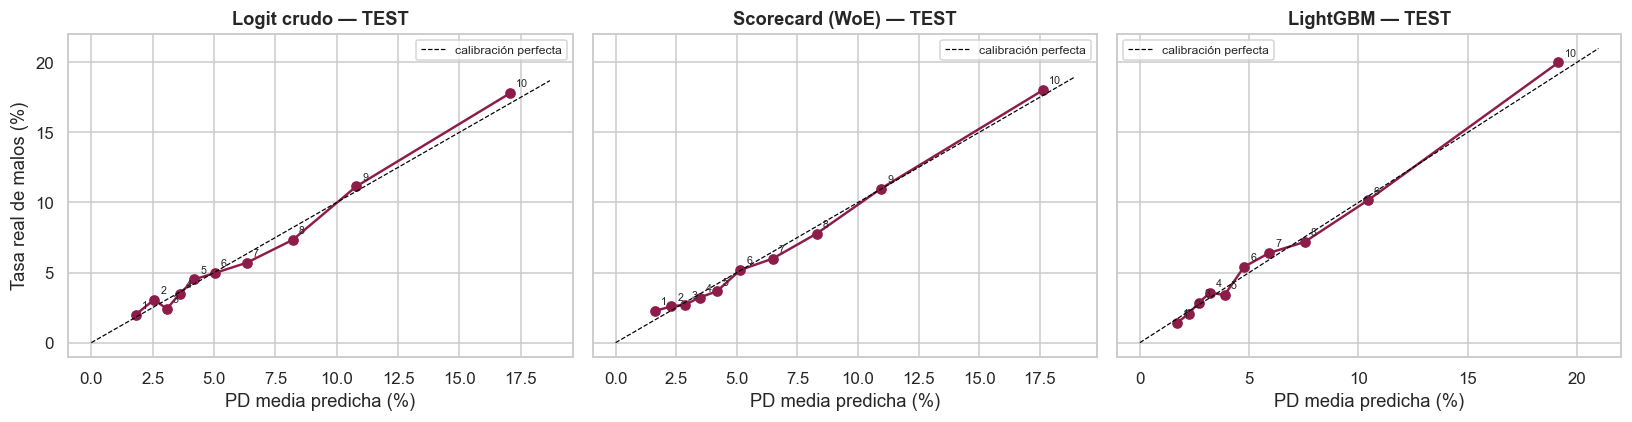

In [30]:
# Calibración por deciles en TEST: PD predicha vs tasa real, para los tres modelos
y_te = te.bad.values          # Y se define en la celda siguiente; aquí no se depende de ella
pd_val_log = logit_base.predict(matriz_cruda(te, COLS_BASE)).values
calib_logit = (pd.DataFrame({"pd": pd_val_log, "y": y_te})
             .assign(decil=lambda d: pd.qcut(d["pd"].rank(method="first"), 10, labels=range(1, 11)))
             .groupby("decil", observed=True).agg(n=("y", "size"), pd_media=("pd", "mean"), tasa_real=("y", "mean"))
             .assign(obs_pred=lambda d: d["tasa_real"] / d["pd_media"]))
display(calib_logit.style.format({"n": "{:,}", "pd_media": "{:.2%}", "tasa_real": "{:.2%}", "obs_pred": "{:.2f}"}))


pd_val_woe = logit.predict(sm.add_constant(woe(te, seleccion), has_constant="add")).values
calib_logitwoe = (pd.DataFrame({"pd": pd_val_woe, "y": y_te})
             .assign(decil=lambda d: pd.qcut(d["pd"].rank(method="first"), 10, labels=range(1, 11)))
             .groupby("decil", observed=True).agg(n=("y", "size"), pd_media=("pd", "mean"), tasa_real=("y", "mean"))
             .assign(obs_pred=lambda d: d["tasa_real"] / d["pd_media"]))
display(calib_logitwoe.style.format({"n": "{:,}", "pd_media": "{:.2%}", "tasa_real": "{:.2%}", "obs_pred": "{:.2f}"}))


pd_val_lgbm = lgbm.predict_proba(X_te)[:, 1]
calib_lgbm  = (pd.DataFrame({"pd": pd_val_lgbm, "y": y_te})
             .assign(decil=lambda d: pd.qcut(d["pd"].rank(method="first"), 10, labels=range(1, 11)))
             .groupby("decil", observed=True).agg(n=("y", "size"), pd_media=("pd", "mean"), tasa_real=("y", "mean"))
             .assign(obs_pred=lambda d: d["tasa_real"] / d["pd_media"]))
display(calib_lgbm.style.format({"n": "{:,}", "pd_media": "{:.2%}", "tasa_real": "{:.2%}", "obs_pred": "{:.2f}"}))


# Gráfico: predicha vs real por decil, un panel por modelo. Los puntos sobre la diagonal = calibración perfecta.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (nombre, c) in zip(axes, [("Logit crudo", calib_logit), ("Scorecard (WoE)", calib_logitwoe), ("LightGBM", calib_lgbm)]):
    ax.plot(c.pd_media * 100, c.tasa_real * 100, "o-", color="#8E1C4A", lw=1.6)
    lim = max(c.pd_media.max(), c.tasa_real.max()) * 100 * 1.05
    ax.plot([0, lim], [0, lim], "k--", lw=.8, label="calibración perfecta")
    for i, (x, y) in enumerate(zip(c.pd_media * 100, c.tasa_real * 100), start=1):
        ax.annotate(str(i), (x, y), textcoords="offset points", xytext=(4, 4), fontsize=7)
    ax.set_title(f"{nombre} — TEST"); ax.set_xlabel("PD media predicha (%)"); ax.legend(fontsize=8)
axes[0].set_ylabel("Tasa real de malos (%)")
plt.tight_layout(); plt.show()

In [31]:
from sklearn.metrics import average_precision_score, f1_score, recall_score,precision_score


def metricas(y, p, nombre, pct_alerta=0.20):
    """Métricas de ranking y calibración (no dependen de un corte) + métricas de clasificación en un corte
    declarado: se alerta al `pct_alerta` de clientes con mayor PD, que es como se usa el modelo (banda E)."""
    y, p = np.asarray(y), np.asarray(p)
    fpr, tpr, _ = roc_curve(y, p)
    auc = roc_auc_score(y, p)
    alerta = (p >= np.quantile(p, 1 - pct_alerta)).astype(int)
    return {"modelo": nombre, "n": len(y), "AUC": auc, "Gini": 2 * auc - 1,
            "KS": float(np.max(tpr - fpr)), "LogLoss": log_loss(y, p, labels=[0, 1]),
            "PD_media": float(p.mean()), "Tasa_real": float(y.mean()), "SumPD/Malos": float(p.sum() / y.sum()),
            "AveragePrecision": average_precision_score(y, p),
            f"Recall@{pct_alerta:.0%}": recall_score(y, alerta, zero_division=0),
            f"Precision@{pct_alerta:.0%}": precision_score(y, alerta, zero_division=0),
            f"F1@{pct_alerta:.0%}": f1_score(y, alerta, zero_division=0)}

# Predicciones de los tres modelos en las tres muestras
pred = {
    "Logit":  {k: logit_base.predict(matriz_cruda(d, COLS_BASE)).values
           for k, d in (("TRAIN", tr), ("TEST", te), ("OOT", oot))},
    "Scorecard":  {k: logit.predict(sm.add_constant(woe(d, seleccion), has_constant="add")).values
                   for k, d in (("TRAIN", tr), ("TEST", te), ("OOT", oot))},
    "Árbol prof.4": {k: arbol.predict_proba(woe(d, seleccion))[:, 1]
                   for k, d in (("TRAIN", tr), ("TEST", te), ("OOT", oot))},
    "LightGBM":   {k: lgbm.predict_proba(X)[:, 1]
                   for k, X in (("TRAIN", X_tr), ("TEST", X_te), ("OOT", X_oot))},
}
Y = {"TRAIN": tr.bad.values, "TEST": te.bad.values, "OOT": oot.bad.values}

tabla = pd.DataFrame([metricas(Y[k], p[k], f"{m} · {k}") for m, p in pred.items() for k in Y])
display(tabla[~tabla["modelo"].str.contains("TRAIN",regex=False)].set_index("modelo").round(4))
print("Nota. Recall, Precision y F1 se miden alertando al 20% de mayor PD de cada muestra (equivale a la banda E).")
print("      AUC, Gini, KS, LogLoss y Average Precision no dependen de ningún corte.")

,n,AUC,Gini,KS,LogLoss,PD_media,Tasa_real,SumPD/Malos,AveragePrecision,Recall@20%,Precision@20%,F1@20%
modelo,,,,,,,,,,,,
Logit · TEST,27024,0.7009,0.4018,0.3027,0.2174,0.0627,0.0624,1.0044,0.1467,0.4638,0.1447,0.2206
Logit · OOT,40304,0.6985,0.3969,0.3029,0.2948,0.0702,0.0940,0.7469,0.1967,0.4384,0.2061,0.2803
Scorecard · TEST,27024,0.7059,0.4118,0.3154,0.2167,0.0629,0.0624,1.0087,0.1496,0.4650,0.1451,0.2211
Scorecard · OOT,40304,0.7016,0.4033,0.3077,0.2933,0.0703,0.0940,0.7477,0.2036,0.4294,0.2018,0.2746
Árbol prof.4 · TEST,27024,0.6835,0.3670,0.2852,0.2203,0.0626,0.0624,1.0038,0.1206,0.4864,0.1289,0.2038
Árbol prof.4 · OOT,40304,0.6817,0.3633,0.2898,0.2986,0.0677,0.0940,0.7205,0.1660,0.4273,0.1924,0.2653
LightGBM · TEST,27024,0.7234,0.4469,0.3300,0.2130,0.0615,0.0624,0.9858,0.1694,0.4828,0.1506,0.2296
LightGBM · OOT,40304,0.7170,0.4340,0.3245,0.2893,0.0703,0.0940,0.7478,0.2214,0.4537,0.2132,0.2901


Nota. Recall, Precision y F1 se miden alertando al 20% de mayor PD de cada muestra (equivale a la banda E).
      AUC, Gini, KS, LogLoss y Average Precision no dependen de ningún corte.


,TRAIN,TEST,OOT,gap TRAIN-TEST
Logit,0.3909,0.4018,0.3969,-0.0109
Scorecard,0.4079,0.4118,0.4033,-0.0039
Árbol prof.4,0.3630,0.3670,0.3633,-0.0040
LightGBM,0.7251,0.4469,0.4340,0.2782


Nota. Una mayor brecha en Gini nos hablaria de overfiting


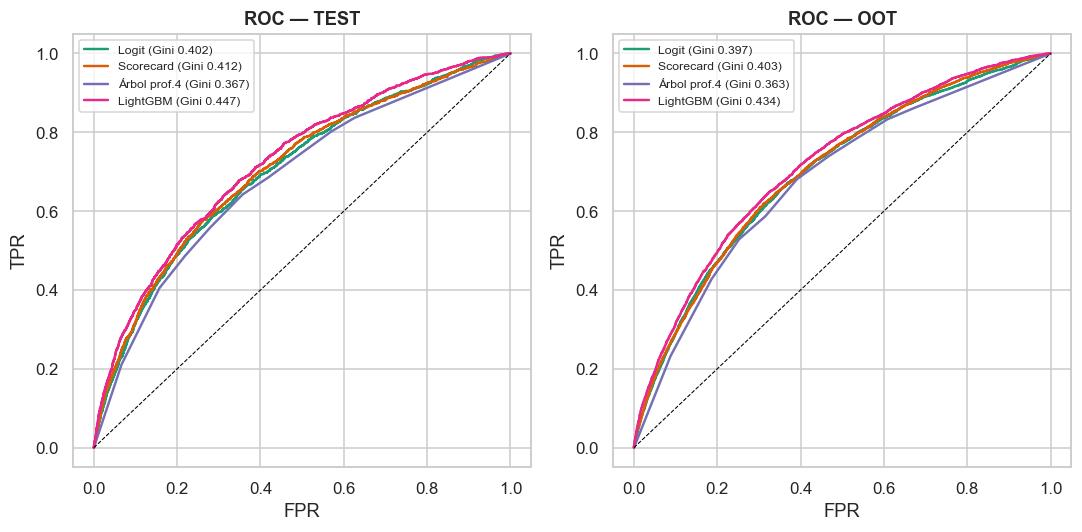

In [32]:
paleta = plt.cm.Dark2.colors 

resumen_gini = pd.DataFrame({m: {k: gini(Y[k], p[k]) for k in Y} for m, p in pred.items()}).T
resumen_gini["gap TRAIN-TEST"] = resumen_gini.TRAIN - resumen_gini.TEST
display(resumen_gini.round(4))
print("Nota. Una mayor brecha en Gini nos hablaria de overfiting")
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for k, a in zip(["TEST", "OOT"], ax):
    a.set_prop_cycle(color=paleta) 
    for m, p in pred.items():
        fpr, tpr, _ = roc_curve(Y[k], p[k])
        a.plot(fpr, tpr, lw=1.6, label=f"{m} (Gini {gini(Y[k], p[k]):.3f})")
    a.plot([0, 1], [0, 1], "k--", lw=.7); a.legend(fontsize=8); a.set_title(f"ROC — {k}")
    a.set_xlabel("FPR"); a.set_ylabel("TPR")
plt.tight_layout(); plt.show()

### Diagnóstico de sobreajuste: gap train vs. validación por fold

Para cada modelo y cada uno de los 5 folds se reentrena con 4/5 de TRAIN y se mide en las filas que vio y en las que no. Un buen resultado en validación no basta; interesa saber **cuánto** del rendimiento es memorización.

Se mira por fold y no solo la media, para distinguir un sesgo sistemático de un accidente de partición.

In [33]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
filas = []
for i, (idx_fit, idx_val) in enumerate(cv.split(W_tr[seleccion], y_tr), start=1):
    # Scorecard
    m = sm.Logit(y_tr[idx_fit], sm.add_constant(W_tr[seleccion].iloc[idx_fit], has_constant="add")).fit(disp=0)
    p_fit = m.predict(sm.add_constant(W_tr[seleccion].iloc[idx_fit], has_constant="add"))
    p_val = m.predict(sm.add_constant(W_tr[seleccion].iloc[idx_val], has_constant="add"))
    filas.append({"Modelo": "Scorecard", "Fold": i, "AUC_train": roc_auc_score(y_tr[idx_fit], p_fit),
                  "AUC_val": roc_auc_score(y_tr[idx_val], p_val),
                  "LogLoss_val": log_loss(y_tr[idx_val], p_val, labels=[0, 1])})
    # LightGBM
    g = LGBMClassifier(**{**busqueda.best_params_, "objective": "binary", "n_estimators": 200,
                          "random_state": SEED, "n_jobs": -1, "verbosity": -1}).fit(X_tr.iloc[idx_fit], y_tr[idx_fit])
    pf, pv = g.predict_proba(X_tr.iloc[idx_fit])[:, 1], g.predict_proba(X_tr.iloc[idx_val])[:, 1]
    filas.append({"Modelo": "LightGBM", "Fold": i, "AUC_train": roc_auc_score(y_tr[idx_fit], pf),
                  "AUC_val": roc_auc_score(y_tr[idx_val], pv),
                  "LogLoss_val": log_loss(y_tr[idx_val], pv, labels=[0, 1])})

gaps = pd.DataFrame(filas)
gaps["Gap_AUC"] = gaps.AUC_train - gaps.AUC_val          # positivo = sobreajuste
display(gaps.groupby("Modelo")[["AUC_train", "AUC_val", "Gap_AUC", "LogLoss_val"]]
            .agg(["mean", "std"]).round(4))
display(gaps.pivot(index="Fold", columns="Modelo", values="Gap_AUC").round(4))

AUC_train        AUC_val        Gap_AUC        LogLoss_val       
               mean    std    mean    std    mean    std        mean    std
Modelo                                                                     
LightGBM     0.8811 0.0019  0.7225 0.0027  0.1585 0.0018      0.2136 0.0010
Scorecard    0.7041 0.0021  0.7031 0.0090  0.0010 0.0111      0.2172 0.0017

Modelo,LightGBM,Scorecard
Fold,,
1,0.1601,-0.0009
2,0.1591,-0.0100
3,0.1555,-0.0092
4,0.1595,0.0130
5,0.1584,0.0120


**Lectura.** El scorecard tiene un gap indistinguible de cero: lo que mide en entrenamiento es lo que mide en datos nuevos. El LightGBM tiene un gap positivo en los cinco folds y con poca dispersión, así que es una propiedad del modelo y no de una partición: el precio de su mayor capacidad. Aun así gana en validación, de modo que el sobreajuste no invalida su ventaja, solo la hace menos predecible.

In [34]:
# ¿La ventaja del LightGBM sobre el scorecard es real y de qué tamaño? Bootstrap pareado sobre OOT.
rng = np.random.default_rng(SEED)
y_o = Y["OOT"]; a, b = pred["Scorecard"]["OOT"], pred["LightGBM"]["OOT"]
dif = [gini(y_o[i], b[i]) - gini(y_o[i], a[i])
       for i in (rng.integers(0, len(y_o), len(y_o)) for _ in range(500))]
lo, med, hi = np.percentile(dif, [2.5, 50, 97.5])
print(f"ΔGini OOT (LightGBM − Scorecard): {med:.4f}   IC95 [{lo:.4f}, {hi:.4f}]")

# Traducción a negocio: al gestionar el 20% más riesgoso, ¿cuántos malos se alcanzan?
captura = lambda p, q=0.20: y_o[p >= np.quantile(p, 1 - q)].sum() / y_o.sum()
print(f"Malos capturados gestionando el 20% peor: "
      f"Scorecard {captura(a):.1%} | LightGBM {captura(b):.1%} | diferencia {captura(b)-captura(a):+.1%}")

ΔGini OOT (LightGBM − Scorecard): 0.0306   IC95 [0.0219, 0.0392]
Malos capturados gestionando el 20% peor: Scorecard 42.9% | LightGBM 45.4% | diferencia +2.4%


### Calibración y ordenamiento

In [35]:
calib = pd.DataFrame({k: {"PD media predicha": pred["Scorecard"][k].mean(), "Tasa real": Y[k].mean()}
                      for k in Y}).T
calib["obs/pred"] = calib["Tasa real"] / calib["PD media predicha"]
display(calib)

# Ajuste de intercepto estimado con el último mes de desarrollo (no se mira OOT para calibrar)
logit_odds = lambda p: np.log(p / (1 - p))
ref = S[(S.PERIODO == 202109)]
p_ref = logit.predict(sm.add_constant(woe(ref, seleccion), has_constant="add")).values
desplazamiento = logit_odds(ref.bad.mean()) - logit_odds(p_ref.mean())
p_recal = 1 / (1 + np.exp(-(logit_odds(pred["Scorecard"]["OOT"]) + desplazamiento)))
print(f"Desplazamiento de intercepto (set-21): {desplazamiento:+.4f}")
print(f"PD media OOT recalibrada: {p_recal.mean():.3%}  vs observada: {Y['OOT'].mean():.3%}")

,PD media predicha,Tasa real,obs/pred
TRAIN,0.0624,0.0624,1.0000
TEST,0.0629,0.0624,0.9913
OOT,0.0703,0.0940,1.3375


Desplazamiento de intercepto (set-21): +0.0679
PD media OOT recalibrada: 7.464%  vs observada: 9.401%


,n,malos,tasa,%malos_acum,lift
decil,,,,,
1,4031,976,0.2421,0.2576,2.5755
2,4030,651,0.1615,0.4294,1.7183
3,4030,530,0.1315,0.5693,1.3989
4,4031,383,0.0950,0.6704,1.0107
5,4030,321,0.0797,0.7551,0.8473
6,4030,266,0.0660,0.8253,0.7021
7,4031,220,0.0546,0.8833,0.5805
8,4030,195,0.0484,0.9348,0.5147
9,4030,141,0.0350,0.9720,0.3722


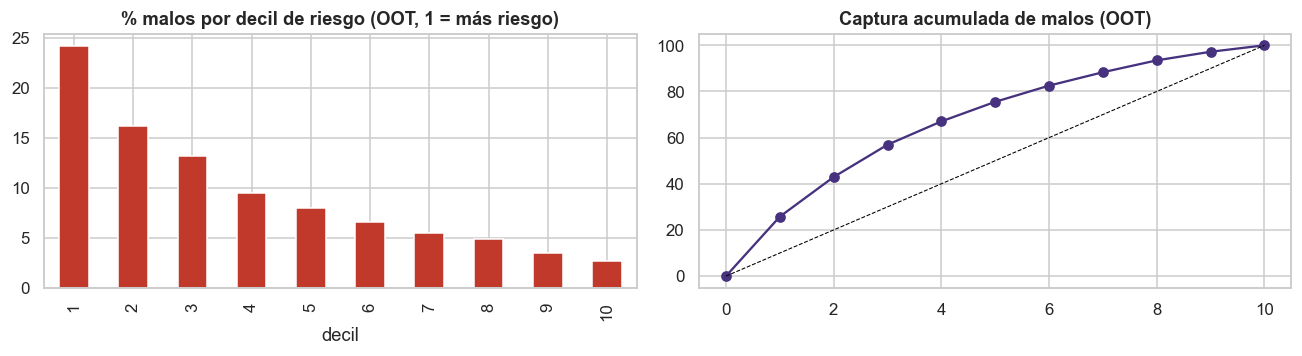

Spearman(decil, tasa) = -1.000
Inversiones entre deciles contiguos: ninguna  (error estándar típico por decil: ±0.46 pts)


In [36]:
d = pd.DataFrame({"y": Y["OOT"], "p": pred["Scorecard"]["OOT"]})
d["decil"] = pd.qcut(d.p.rank(method="first", ascending=False), 10, labels=range(1, 11))
deciles = d.groupby("decil", observed=True).agg(n=("y", "size"), malos=("y", "sum"), tasa=("y", "mean"))
deciles["%malos_acum"] = deciles.malos.cumsum() / deciles.malos.sum()
deciles["lift"] = deciles.tasa / d.y.mean()
display(deciles.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
(deciles.tasa * 100).plot.bar(ax=ax[0], color="#c0392b")
ax[0].set_title("% malos por decil de riesgo (OOT, 1 = más riesgo)")
ax[1].plot(range(0, 11), [0] + list(deciles["%malos_acum"] * 100), marker="o")
ax[1].plot([0, 10], [0, 100], "k--", lw=.7); ax[1].set_title("Captura acumulada de malos (OOT)")
plt.tight_layout(); plt.show()

error_std = np.sqrt(d.y.mean() * (1 - d.y.mean()) / deciles.n.mean()) * 100
inversiones = [(int(i), int(j)) for i, j in zip(deciles.index[:-1], deciles.index[1:])
               if deciles.tasa[j] > deciles.tasa[i]]
print(f"Spearman(decil, tasa) = {stats.spearmanr(deciles.index.astype(int), deciles.tasa)[0]:.3f}")
print(f"Inversiones entre deciles contiguos: {inversiones or 'ninguna'}  "
      f"(error estándar típico por decil: ±{error_std:.2f} pts)")

**Lectura.** El modelo **ordena bien pero subestima el nivel**: la PD media predicha queda por debajo de la tasa real en OOT, porque la cartera se deterioró después del periodo de desarrollo. Eso no afecta al Gini, al KS ni a las bandas, que dependen solo del ranking, pero sí afectaría cualquier uso de la PD para provisiones o precios. El ajuste de intercepto corrige una parte: la recalibración se estima con el último mes de desarrollo, no con OOT, para no contaminar la validación.

Las inversiones entre deciles contiguos, si aparecen, hay que compararlas con el error estándar por decil antes de llamarlas un fallo de ordenamiento.

## 10. Decisión del modelo

**La elección se pondera con TEST.** Poder predictivo = Gini en TEST; robustez = brecha TRAIN–TEST (sobreajuste). Las tres dimensiones restantes son **criterio experto declarado**, no medición.

**OOT entra solo al final, como compuerta de validación** (si falla, el modelo elegido se descarta): Gini OOT ≥ 0.30 · KS ≥ 0.25 · PSI del score < 0.25 · signos coherentes · sin variables protegidas. Así OOT confirma la decisión pero no la toma.

In [37]:
# Costo de las exclusiones por política: ¿cuánto Gini se resigna?
S_pol = S.copy()
S_pol["DEPARTAMENTO"] = S_pol["DEPARTAMENTO"].astype("category").cat.codes
politica = {}
for nombre, (nums, cats) in {
        "Sin variables de política": (NUMERICAS, CATEGORICAS),
        "Con GENERO + ESTADO_CIVIL + DEPARTAMENTO": (NUMERICAS + ["ESTADO_CIVIL", "DEPARTAMENTO"], CATEGORICAS + ["GENERO"])}.items():
    niv = {c: sorted(S_pol[S_pol.split == "TRAIN"][c].dropna().unique()) for c in cats}
    marco = lambda d: d[nums + cats].assign(**{c: pd.Categorical(d[c], categories=niv[c]) for c in cats})
    m = LGBMClassifier(**{**busqueda.best_params_, "objective": "binary", "n_estimators": 200,
                          "random_state": SEED, "n_jobs": -1, "verbosity": -1})
    m.fit(marco(S_pol[S_pol.split == "TRAIN"]), S_pol[S_pol.split == "TRAIN"].bad)
    politica[nombre] = {k: gini(S_pol[S_pol.split == k].bad, m.predict_proba(marco(S_pol[S_pol.split == k]))[:, 1])
                        for k in ("TEST", "OOT")}
politica = pd.DataFrame(politica).T
politica["Δ OOT"] = politica.OOT - politica.OOT.iloc[0]
display(politica.round(4))
print("Ese Δ es el precio de la decisión de política de la sección 2. Se declara, no se esconde.")

,TEST,OOT,Δ OOT
Sin variables de política,0.4469,0.4340,0.0000
Con GENERO + ESTADO_CIVIL + DEPARTAMENTO,0.4622,0.4489,0.0149


Ese Δ es el precio de la decisión de política de la sección 2. Se declara, no se esconde.


In [38]:
# La matriz se puntúa con TEST; OOT se reserva para la compuerta final (abajo)
g_te = {m: gini(Y["TEST"], p["TEST"]) for m, p in pred.items()}
brecha = {m: abs(gini(Y["TRAIN"], p["TRAIN"]) - g_te[m]) for m, p in pred.items()}   # sobreajuste

lo_g, hi_g = min(g_te.values()), max(g_te.values())
nota_brecha = lambda x: 5 if x <= .02 else 4 if x <= .05 else 3 if x <= .10 else 2 if x <= .15 else 1
cualitativo = {
    "Scorecard":    [5, 5, 5],      # explicabilidad, implementación, gobierno
    "Árbol prof.4": [4, 4, 3],
    "LightGBM":     [2, 2, 2],
    "Logit":        [4, 3, 3],      # logit crudo: coeficientes legibles pero sin tabla de puntos;
                                    # necesita imputación y dummies en producción, y 30+ dummies de GRADO son difíciles de gobernar
}  # criterio experto
PESOS = {"Poder predictivo": .25, "Robustez": .20, "Interpretabilidad": .25,
         "Implementación": .15, "Explicación de rechazos y equidad": .15}

M = pd.DataFrame({m: [1 + 4 * (g_te[m] - lo_g) / ((hi_g - lo_g) or 1e-9), nota_brecha(brecha[m]), *cualitativo[m]]
                  for m in pred}, index=list(PESOS)).T
M["TOTAL"] = sum(M[c] * w for c, w in PESOS.items())
display(M.round(2).sort_values("TOTAL", ascending=False))

escenarios = {"Base": list(PESOS.values()), "Gini 50%": [.50, .20, .10, .10, .10],
              "Solo estadístico (70/30)": [.70, .30, 0, 0, 0]}
sens = pd.DataFrame({k: (M[list(PESOS)] * np.array(w)).sum(axis=1) for k, w in escenarios.items()})
display(sens.round(2))
print("Ganador por escenario:", sens.idxmax().to_dict())

# Compuerta final con OOT: confirma (o veta) al modelo elegido; no participa en el ranking
g_oot = {m: gini(Y["OOT"], p["OOT"]) for m, p in pred.items()}
ks_oot = {m: metricas(Y["OOT"], p["OOT"], m)["KS"] for m, p in pred.items()}
compuertas = pd.DataFrame({"Gini TEST": g_te, "Gini OOT": g_oot, "KS OOT": ks_oot,
                           "Pasa compuerta OOT": {m: g_oot[m] >= .30 and ks_oot[m] >= .25 for m in g_oot}})
display(compuertas.round(4))
elegido = M.TOTAL.idxmax()
print(f"Elegido con TEST: {elegido} | ¿pasa la compuerta OOT?: {compuertas.loc[elegido, 'Pasa compuerta OOT']}")

,Poder predictivo,Robustez,Interpretabilidad,Implementación,Explicación de rechazos y equidad,TOTAL
Scorecard,3.2400,5.0000,5.0000,5.0000,5.0000,4.5600
Logit,2.7400,5.0000,4.0000,3.0000,3.0000,3.5900
Árbol prof.4,1.0000,5.0000,4.0000,4.0000,3.0000,3.3000
LightGBM,5.0000,1.0000,2.0000,2.0000,2.0000,2.5500


,Base,Gini 50%,Solo estadístico (70/30)
Logit,3.5900,3.3700,3.4200
Scorecard,4.5600,4.1200,3.7700
Árbol prof.4,3.3000,2.6000,2.2000
LightGBM,2.5500,3.3000,3.8000


Ganador por escenario: {'Base': 'Scorecard', 'Gini 50%': 'Scorecard', 'Solo estadístico (70/30)': 'LightGBM'}


,Gini TEST,Gini OOT,KS OOT,Pasa compuerta OOT
Logit,0.4018,0.3969,0.3029,True
Scorecard,0.4118,0.4033,0.3077,True
Árbol prof.4,0.3670,0.3633,0.2898,True
LightGBM,0.4469,0.4340,0.3245,True


Elegido con TEST: Scorecard | ¿pasa la compuerta OOT?: True


**Decisión: champion = Scorecard, challenger = LightGBM.**

El LightGBM gana en poder predictivo y la diferencia es estadísticamente distinguible de cero, pero de magnitud moderada: en términos de negocio, gestionar el 20% más riesgoso captura apenas un punto porcentual más de mora. A cambio es una caja negra, con una brecha train-validación mucho mayor y un costo de gobierno superior. Se mantiene como benchmark de monitoreo y como fuente de variables para la siguiente versión del scorecard.

**La sensibilidad, dicha de frente:** si la decisión se tomara solo con criterios estadísticos, ganaría el LightGBM. La recomendación descansa en interpretabilidad, validación independiente y capacidad de explicar un rechazo —lo que exige la gestión de riesgo de modelo (Res. SBS 53-2023)— y no en superioridad estadística. Presentar la matriz sin su sensibilidad sería vender la decisión como obvia cuando no lo es.

## 11. Scorecard, bandas y punto de corte

Escala estándar del sector: **600 puntos = odds 50:1** (bueno:malo) y **+20 puntos duplican el odds**. El score es la suma de los puntos de cada atributo, de modo que la tabla que se entrega a negocio *es* el modelo, no una aproximación. La última línea de la celda lo verifica.

In [39]:
PDO, SCORE_BASE, ODDS_BASE = 20, 600, 50
factor = PDO / np.log(2)
offset = SCORE_BASE - factor * np.log(ODDS_BASE)
a_score = lambda p: offset + factor * np.log((1 - np.clip(p, 1e-6, 1 - 1e-6)) / np.clip(p, 1e-6, 1 - 1e-6))

# Tabla de puntos por atributo
n_v = len(seleccion)
filas_puntos = []
for v in seleccion:
    t = bins[v].binning_table.build()
    t = t[(t.index != "Totals") & (t["Count"] > 0)]
    for _, r in t.iterrows():
        filas_puntos.append({"variable": v, "atributo": str(r["Bin"]), "n": int(r["Count"]),
                      "%clientes": r["Count (%)"], "tasa_malos": r["Event rate"], "WoE": r["WoE"],
                      "puntos": round(-(logit.params[v] * r["WoE"] + logit.params["const"] / n_v) * factor + offset / n_v, 1)})
puntos = pd.DataFrame(filas_puntos)

peso = puntos.groupby("variable").puntos.agg(lambda s: s.max() - s.min()).sort_values(ascending=False)
display(peso.to_frame("rango de puntos"))

# Verificación: la suma de puntos reproduce el score derivado de la PD
suma = sum(-(logit.params[v] * W_tr[v] + logit.params["const"] / n_v) * factor + offset / n_v for v in seleccion)
print(f"Diferencia máxima entre 'suma de puntos' y 'score desde la PD': "
      f"{np.abs(suma - a_score(logit.predict(sm.add_constant(W_tr[seleccion], has_constant='add')))).max():.10f}")

,rango de puntos
variable,
MAX_LINEA12,17.9000
INT_SALDO,14.8000
D12_MAXD,13.1000
GRADO_INSTRUCCION,12.9000
MAX_RATIO_PRES6,12.0000
PROMDIR_IND12,12.0000
SITUACION_LABORAL,11.9000
MESES_ANT_RCC,11.8000
MAX_GARAN_SALDO6,10.9000


Diferencia máxima entre 'suma de puntos' y 'score desde la PD': 0.0000000000


In [40]:
S = S.assign(score=np.nan)
for k, d in (("TRAIN", tr), ("TEST", te), ("OOT", oot)):
    S.loc[S.split == k, "score"] = a_score(pred["Scorecard"][k])

cortes_banda = S.loc[S.split == "TRAIN", "score"].quantile([.2, .4, .6, .8]).values
ETIQUETAS = ["E · muy alto", "D · alto", "C · medio", "B · bajo", "A · muy bajo"]
S["banda"] = pd.cut(S.score, [-np.inf, *cortes_banda, np.inf], labels=ETIQUETAS)

tabla_bandas = S.groupby(["banda", "split"], observed=True).agg(n=("bad", "size"), tasa=("bad", "mean")).unstack("split")
display((tabla_bandas["tasa"] * 100).round(2).loc[ETIQUETAS[::-1]].add_prefix("% malos "))
display((pd.crosstab(S.banda, S.split, normalize="columns") * 100).round(1).loc[ETIQUETAS[::-1]].add_prefix("% clientes "))

o = S[S.split == "OOT"]
cortes = pd.DataFrame([{"% gestionado": q, "score de corte": o.score.quantile(q),
                        "malos capturados": o.bad[o.score <= o.score.quantile(q)].sum() / o.bad.sum(),
                        "mora de los no gestionados": o.bad[o.score > o.score.quantile(q)].mean()}
                       for q in (0.05, 0.10, 0.15, 0.20, 0.30)])
display(cortes.round(4))
print(f"Tasa de default de la cartera OOT: {o.bad.mean():.2%}")
print("El punto de corte lo decide negocio: apetito de riesgo, margen por cliente y costo de la mora.")

split,% malos OOT,% malos TEST,% malos TRAIN
banda,,,
A · muy bajo,3.0500,2.4900,2.2000
B · bajo,4.8000,2.8900,3.2500
C · medio,6.5100,4.4100,4.4100
D · alto,9.8900,6.8000,7.3300
E · muy alto,18.8100,14.4900,14.0200


split,% clientes OOT,% clientes TEST,% clientes TRAIN
banda,,,
A · muy bajo,18.1000,20.2000,20.0000
B · bajo,17.6000,20.0000,20.0000
C · medio,18.5000,19.5000,20.0000
D · alto,20.3000,20.1000,20.0000
E · muy alto,25.5000,20.3000,20.0000


,% gestionado,score de corte,malos capturados,mora de los no gestionados
0,0.0500,529.9160,0.1502,0.0841
1,0.1000,537.4347,0.2576,0.0776
2,0.1500,543.2667,0.3473,0.0722
3,0.2000,548.0963,0.4294,0.0671
4,0.3000,556.5651,0.5693,0.0579


Tasa de default de la cartera OOT: 9.40%
El punto de corte lo decide negocio: apetito de riesgo, margen por cliente y costo de la mora.


Tasa de default de la cartera OOT: 9.40%
Average Precision (no depende del corte): 0.2036  | piso de un modelo sin información = tasa base = 0.0940
El punto de corte lo decide negocio: apetito de riesgo, margen por cliente y costo de la mora.



,% cartera alertada,mora en alertados (precision),malos capturados (recall),F1,lift,mora en NO alertados
corte,,,,,,
10% más riesgoso (score < 537),0.100015,0.242124,0.257588,0.250,2.58x,7.76%
20% más riesgoso (score < 548),0.200005,0.201836,0.429401,0.275,2.15x,6.71%
30% más riesgoso (score < 557),0.299970,0.178412,0.569279,0.272,1.90x,5.78%
40% más riesgoso (score < 564),0.400010,0.157549,0.670362,0.255,1.68x,5.16%
50% más riesgoso (score < 571),0.499975,0.141978,0.755080,0.239,1.51x,4.60%
banda E,0.254665,0.188133,0.509633,0.275,2.00x,6.19%
bandas E + D,0.457275,0.148616,0.722882,0.247,1.58x,4.80%
PD ≥ tasa base (9.4%),0.251538,0.189189,0.506202,0.275,2.01x,6.20%


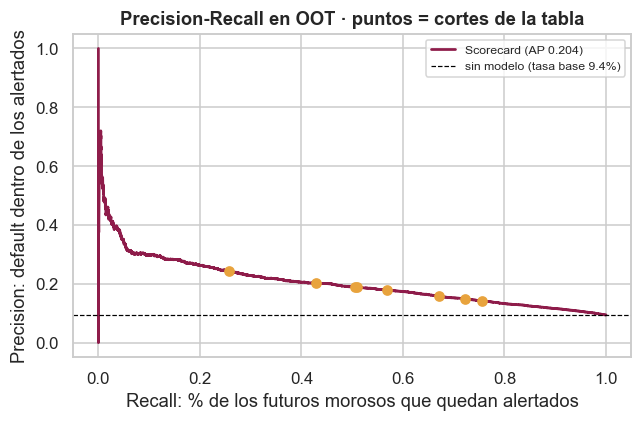

In [41]:
# ── Punto de corte: ¿a quién alertar? ────────────────────────────────────────
# El modelo ordena; dónde cortar es una decisión de negocio (capacidad de cobranza, costo de contactar
# a un bueno, costo de no contactar a un malo). Aquí se muestra el menú de cortes con sus consecuencias.
oot_s = S[S.split == "OOT"]
y_oot = oot_s.bad.values
p_oot = pred["Scorecard"]["OOT"]
tasa_oot = y_oot.mean()

print(f"Tasa de default de la cartera OOT: {tasa_oot:.2%}")
print(f"Average Precision (no depende del corte): {average_precision_score(y_oot, p_oot):.4f}  "
      f"| piso de un modelo sin información = tasa base = {tasa_oot:.4f}")
print("El punto de corte lo decide negocio: apetito de riesgo, margen por cliente y costo de la mora.\n")

def medidas_corte(nombre, alerta):
    """alerta: vector booleano, True = cliente marcado para gestión."""
    y_pred = alerta.astype(int)
    return {"corte": nombre,
            "% cartera alertada": alerta.mean(),
            "mora en alertados (precision)": precision_score(y_oot, y_pred, zero_division=0),
            "malos capturados (recall)": recall_score(y_oot, y_pred, zero_division=0),
            "F1": f1_score(y_oot, y_pred, zero_division=0),
            "lift": precision_score(y_oot, y_pred, zero_division=0) / tasa_oot,
            "mora en NO alertados": y_oot[~alerta].mean() if (~alerta).any() else np.nan}

filas_corte = []
for pct in [.10, .20, .30, .40, .50]:                          # cortes por capacidad: gestionar el X% más riesgoso
    umbral = np.quantile(oot_s.score, pct)
    filas_corte.append(medidas_corte(f"{pct:.0%} más riesgoso (score < {umbral:.0f})", (oot_s.score < umbral).values))
for bandas, nombre in [(["E · muy alto"], "banda E"), (["E · muy alto", "D · alto"], "bandas E + D")]:
    filas_corte.append(medidas_corte(nombre, oot_s.banda.isin(bandas).values))
filas_corte.append(medidas_corte(f"PD ≥ tasa base ({tasa_oot:.1%})", p_oot >= tasa_oot))

cortes = pd.DataFrame(filas_corte).set_index("corte")
display(cortes.style.format({"% Clientes alertada": "{:.1%}", "precision": "{:.2%}",
                             "recall": "{:.1%}", "F1": "{:.3f}", "lift": "{:.2f}x",
                             "mora en NO alertados": "{:.2%}"})
              .background_gradient(subset=["malos capturados (recall)"], cmap="Greens"))

# Curva precision-recall: todos los cortes posibles en un solo gráfico
from sklearn.metrics import precision_recall_curve
prec, rec, _ = precision_recall_curve(y_oot, p_oot)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rec, prec, color="#8E1C4A", lw=1.8, label=f"Scorecard (AP {average_precision_score(y_oot, p_oot):.3f})")
ax.axhline(tasa_oot, color="k", ls="--", lw=.8, label=f"sin modelo (tasa base {tasa_oot:.1%})")
for _, r in cortes.iterrows():
    ax.plot(r["malos capturados (recall)"], r["mora en alertados (precision)"], "o", color="#E8A33D", ms=6)
ax.set_xlabel("Recall: % de los futuros morosos que quedan alertados")
ax.set_ylabel("Precision: default dentro de los alertados")
ax.set_title("Precision-Recall en OOT · puntos = cortes de la tabla"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [42]:
# ── Beneficio por priorización: qué se gana con cada corte ───────────────────
# Supuestos de negocio (declarados, para que negocio los cambie): costo de gestionar un cliente alertado,
# pérdida promedio que genera un moroso early y qué fracción de esa pérdida evita la gestión temprana.
COSTO_GESTION  = 15      # S/ por cliente alertado (llamada + seguimiento)
PERDIDA_MOROSO = 600     # S/ pérdida esperada por cliente que entra a mora early sin gestión
EFECTIVIDAD    = 0.30    # fracción de la pérdida que evita alertar a tiempo (cura, refinanciación, pago parcial)

n_oot, malos_oot = len(y_oot), int(y_oot.sum())

beneficio = cortes.assign(
    clientes_alertados   = lambda d: (d["% cartera alertada"] * n_oot).round().astype(int),
    malos_capturados     = lambda d: (d["malos capturados (recall)"] * malos_oot).round().astype(int),
    malos_no_alertados   = lambda d: malos_oot - d.malos_capturados,
    buenos_alertados     = lambda d: d.clientes_alertados - d.malos_capturados,
    costo_gestion        = lambda d: d.clientes_alertados * COSTO_GESTION,
    perdida_evitada      = lambda d: d.malos_capturados * PERDIDA_MOROSO * EFECTIVIDAD,
    beneficio_neto       = lambda d: d.perdida_evitada - d.costo_gestion,
    beneficio_por_alerta = lambda d: d.beneficio_neto / d.clientes_alertados,
)[["clientes_alertados", "malos_capturados", "malos_no_alertados", "buenos_alertados",
   "costo_gestion", "perdida_evitada", "beneficio_neto", "beneficio_por_alerta"]]

display(beneficio.style.format({"clientes_alertados": "{:,}", "malos_capturados": "{:,}", "malos_no_alertados": "{:,}",
                                "buenos_alertados": "{:,}", "costo_gestion": "S/ {:,.0f}", "perdida_evitada": "S/ {:,.0f}",
                                "beneficio_neto": "S/ {:,.0f}", "beneficio_por_alerta": "S/ {:,.1f}"})
                 .background_gradient(subset=["beneficio_neto"], cmap="Greens"))

# Análisis marginal: ¿qué aporta cada 10% adicional de cartera? Muestra los rendimientos decrecientes.
esc = beneficio.loc[[c for c in beneficio.index if "más riesgoso" in c]].copy()
esc["malos extra por tramo"]     = esc.malos_capturados.diff().fillna(esc.malos_capturados).astype(int)
esc["alertas extra por tramo"]   = esc.clientes_alertados.diff().fillna(esc.clientes_alertados).astype(int)
esc["mora marginal del tramo"]   = esc["malos extra por tramo"] / esc["alertas extra por tramo"]
esc["beneficio marginal (S/)"]   = esc.beneficio_neto.diff().fillna(esc.beneficio_neto)
display(esc[["malos extra por tramo", "alertas extra por tramo", "mora marginal del tramo", "beneficio marginal (S/)"]]
        .style.format({"mora marginal del tramo": "{:.2%}", "beneficio marginal (S/)": "S/ {:,.0f}"}))

print(f"Mora marginal de equilibrio: {COSTO_GESTION / (PERDIDA_MOROSO * EFECTIVIDAD):.2%}  "
      f"-> conviene seguir ampliando la alerta mientras el tramo adicional tenga más mora que esto.")
print(f"Corte de máximo beneficio neto con estos supuestos: {beneficio.beneficio_neto.idxmax()}")

,clientes_alertados,malos_capturados,malos_no_alertados,buenos_alertados,costo_gestion,perdida_evitada,beneficio_neto,beneficio_por_alerta
corte,,,,,,,,
10% más riesgoso (score < 537),"4,031",976,"2,813","3,055","S/ 60,465","S/ 175,680","S/ 115,215",S/ 28.6
20% más riesgoso (score < 548),"8,061","1,627","2,162","6,434","S/ 120,915","S/ 292,860","S/ 171,945",S/ 21.3
30% más riesgoso (score < 557),"12,090","2,157","1,632","9,933","S/ 181,350","S/ 388,260","S/ 206,910",S/ 17.1
40% más riesgoso (score < 564),"16,122","2,540","1,249","13,582","S/ 241,830","S/ 457,200","S/ 215,370",S/ 13.4
50% más riesgoso (score < 571),"20,151","2,861",928,"17,290","S/ 302,265","S/ 514,980","S/ 212,715",S/ 10.6
banda E,"10,264","1,931","1,858","8,333","S/ 153,960","S/ 347,580","S/ 193,620",S/ 18.9
bandas E + D,"18,430","2,739","1,050","15,691","S/ 276,450","S/ 493,020","S/ 216,570",S/ 11.8
PD ≥ tasa base (9.4%),"10,138","1,918","1,871","8,220","S/ 152,070","S/ 345,240","S/ 193,170",S/ 19.1


,malos extra por tramo,alertas extra por tramo,mora marginal del tramo,beneficio marginal (S/)
corte,,,,
10% más riesgoso (score < 537),976,4031,24.21%,"S/ 115,215"
20% más riesgoso (score < 548),651,4030,16.15%,"S/ 56,730"
30% más riesgoso (score < 557),530,4029,13.15%,"S/ 34,965"
40% más riesgoso (score < 564),383,4032,9.50%,"S/ 8,460"
50% más riesgoso (score < 571),321,4029,7.97%,"S/ -2,655"


Mora marginal de equilibrio: 8.33%  -> conviene seguir ampliando la alerta mientras el tramo adicional tenga más mora que esto.
Corte de máximo beneficio neto con estos supuestos: bandas E + D


## 12. Replicabilidad y resultado final

La prueba que pedía el caso: aplicar el modelo —entrenado sobre la muestra— a los clientes que **nunca** entraron en ella. Si `SAMPLE_FRAC = 1.0` no hay población fuera de muestra y el bloque lo indica.

In [43]:
if SAMPLE_FRAC < 1:
    resto = df[~df.serie.isin(S.serie)]
    p_resto = logit.predict(sm.add_constant(woe(resto, seleccion), has_constant="add")).values
    rep = pd.DataFrame({k: {"n": int((resto.split == k).sum()),
                            "Gini (no muestreados)": gini(resto.bad[resto.split == k], p_resto[(resto.split == k).values]),
                            "Gini (muestra)": gini(Y[k], pred["Scorecard"][k])}
                        for k in ("TRAIN", "TEST", "OOT")}).T
    display(rep.round(4))
    print("Si el Gini se sostiene en clientes nunca vistos, el modelo no depende de la muestra.")
else:
    print("SAMPLE_FRAC = 1.0: el modelo ya está entrenado sobre la base completa, no hay población fuera de muestra.")

SAMPLE_FRAC = 1.0: el modelo ya está entrenado sobre la base completa, no hay población fuera de muestra.


In [44]:
print("=" * 74)
print("MODELO EARLY DE MOROSIDAD — RESULTADO FINAL".center(74))
print("=" * 74)
print(f"Base                  : {len(df):,} clientes | {raw.shape[1]} variables | abr-nov 2021")
print(f"Muestra de desarrollo : {len(S):,} clientes ({len(S)/len(df):.0%})   [SAMPLE_FRAC = {SAMPLE_FRAC}]")
print(f"Partición             : TRAIN {len(tr):,} | TEST {len(te):,} | OOT {len(oot):,}")
print("-" * 74)
print(f"Modelo elegido        : Scorecard (WoE + regresión logística), {len(seleccion)} variables")
print(f"Gini   TRAIN / TEST / OOT : {gini(Y['TRAIN'], pred['Scorecard']['TRAIN']):.4f} / "
      f"{gini(Y['TEST'], pred['Scorecard']['TEST']):.4f} / {gini(Y['OOT'], pred['Scorecard']['OOT']):.4f}")
print(f"KS OOT                    : {metricas(Y['OOT'], pred['Scorecard']['OOT'], '')['KS']:.4f}")
print(f"Calibración OOT (obs/pred): {Y['OOT'].mean() / pred['Scorecard']['OOT'].mean():.3f}")
print(f"Challenger LightGBM, Gini OOT : {gini(Y['OOT'], pred['LightGBM']['OOT']):.4f} "
      f"(ventaja {gini(Y['OOT'], pred['LightGBM']['OOT']) - gini(Y['OOT'], pred['Scorecard']['OOT']):+.4f})")
print("-" * 74)
print(f"Captura de mora gestionando el 20% peor : {captura(pred['Scorecard']['OOT']):.1%}")
print(f"Mora banda A (muy bajo) vs E (muy alto) : "
      f"{S[(S.split=='OOT') & (S.banda=='A · muy bajo')].bad.mean():.2%} vs "
      f"{S[(S.split=='OOT') & (S.banda=='E · muy alto')].bad.mean():.2%}")
print("=" * 74)
print("\nVariables del modelo:")
for i, v in enumerate(seleccion, 1):
    print(f"  {i:>2}. {v:<24} {peso[v]:>5.1f} pts de rango")

               MODELO EARLY DE MOROSIDAD — RESULTADO FINAL                
Base                  : 130,184 clientes | 157 variables | abr-nov 2021
Muestra de desarrollo : 130,184 clientes (100%)   [SAMPLE_FRAC = 1]
Partición             : TRAIN 62,856 | TEST 27,024 | OOT 40,304
--------------------------------------------------------------------------
Modelo elegido        : Scorecard (WoE + regresión logística), 14 variables
Gini   TRAIN / TEST / OOT : 0.4079 / 0.4118 / 0.4033
KS OOT                    : 0.3077
Calibración OOT (obs/pred): 1.337
Challenger LightGBM, Gini OOT : 0.4340 (ventaja +0.0307)
--------------------------------------------------------------------------
Captura de mora gestionando el 20% peor : 42.9%
Mora banda A (muy bajo) vs E (muy alto) : 3.05% vs 18.81%

Variables del modelo:
   1. MAX_LINEA12               17.9 pts de rango
   2. MESES_ANT_RCC             11.8 pts de rango
   3. D12_MAXD                  13.1 pts de rango
   4. SITUACION_LABORAL         11.9 

### Lo que queda pendiente antes de producción

| Pendiente | Estado medido | Acción |
|---|---|---|
| **Calibración** | la PD subestima el nivel reciente | recalibrar el intercepto con la ventana más reciente |
| **Equidad** | el modelo no usa género, pero hay variables que actúan como proxy | medir razón de aprobación y obs/pred por grupo; revisar con Cumplimiento |
| **Circularidad de `INT_SALDO`** | PSI 0.005 y pricing estable en la ventana (cuidado con clientes exclusivos) | monitorear su PSI cada mes; un cambio en la política de precios dispara revalidación del modelo |
| **Estabilidad** | PSI del score en verde, con una variable cerca del umbral | monitoreo mensual con semáforos |
| **Gobierno** | — | categorización por materialidad, inventario, validación independiente y back-testing (Res. SBS 53-2023) |

**Limitaciones del caso:** el horizonte del evento no está documentado; hay solo 8 meses de historia post-pandemia y el OOT son 2 meses; la base no incluye ingresos, comportamiento interno ni clientes rechazados, y el evento resultó casi independiente del atraso previo, lo que sugiere pedir datos de pago más finos para una próxima versión.

## 13. Exportación para el aplicativo de gestión del modelo

Última celda del proyecto: deja en `modelo_export/` lo que necesita el aplicativo `app_gestion_modelo.py` para
funcionar **sin volver a leer la base original**: el modelo (binning + coeficientes + escala), la ficha de cada
variable, la tabla de puntos por atributo, el score de cada cliente y los resultados del experimento de reglas.

In [45]:
import pickle
from pathlib import Path

EXPORT = Path("modelo_export"); EXPORT.mkdir(exist_ok=True)

# 1 ── Modelo: lo mínimo para volver a puntuar un cliente desde cero
pickle.dump({
    "seleccion": seleccion,
    "bins": {v: bins[v] for v in seleccion},
    "coeficientes": logit.params.to_dict(),
    "escala": {"PDO": PDO, "score_base": SCORE_BASE, "odds_base": ODDS_BASE,
               "factor": float(factor), "offset": float(offset)},
    "cortes_banda": [float(x) for x in cortes_banda],
    "etiquetas_banda": ETIQUETAS,
    "familia": {v: familia(v) for v in seleccion},
    "categoricas": [v for v in seleccion if v in CATEGORICAS],
    "niveles": {v: [str(x) for x in sorted(tr[v].dropna().unique())] for v in seleccion if v in CATEGORICAS},
    "moda": {v: str(tr[v].mode().iloc[0]) for v in seleccion if v in CATEGORICAS},
    "rangos": {v: {"mediana": float(tr[v].median()), "p01": float(tr[v].quantile(.01)),
                   "p99": float(tr[v].quantile(.99)), "pct_faltante": float(tr[v].isna().mean())}
               for v in seleccion if v not in CATEGORICAS},
}, open(EXPORT / "modelo.pkl", "wb"))

# 2 ── Ficha de cada variable del modelo
ficha = pd.DataFrame({
    "familia": {v: familia(v) for v in seleccion},
    "IV": IV.IV.reindex(seleccion),
    "PSI_TRAIN_OOT": estabilidad.reindex(seleccion),
    "pct_faltante": tr[seleccion].isna().mean(),
    "coeficiente": logit.params.reindex(seleccion),
    "p_valor": logit.pvalues.reindex(seleccion),
    "VIF": resumen.VIF.reindex(seleccion),
    "peso_puntos": peso.reindex(seleccion),
}).rename_axis("variable")
ficha.to_csv(EXPORT / "variables.csv")

# 3 ── Tabla de puntos por atributo y score de cada cliente
puntos.to_csv(EXPORT / "puntos.csv", index=False)

clientes = S[["serie", "PERIODO", "split", "bad", "score", "banda"]].copy()
clientes["PD"] = np.nan
for k in ("TRAIN", "TEST", "OOT"):
    clientes.loc[clientes.split == k, "PD"] = pred["Scorecard"][k]
for v in seleccion:                                      # puntos que aporta cada variable
    w = woe(S, [v])[v]
    clientes["pts_" + v] = -(logit.params[v] * w + logit.params["const"] / n_v) * factor + offset / n_v
clientes.to_parquet(EXPORT / "clientes.parquet", index=False)

# 4 ── Resultados: métricas, deciles, cortes, política y experimento de reglas
tabla.to_csv(EXPORT / "metricas.csv", index=False)
deciles.to_csv(EXPORT / "deciles.csv")
cortes.to_csv(EXPORT / "cortes.csv", index=False)
politica.to_csv(EXPORT / "politica.csv")
experimento_reglas.to_csv(EXPORT / "reglas.csv")
auditoria.rename("regla").to_frame().to_csv(EXPORT / "auditoria_reglas.csv")
gaps.to_csv(EXPORT / "gap_folds.csv", index=False)
M.round(3).to_csv(EXPORT / "matriz_decision.csv")
sens.round(3).to_csv(EXPORT / "sensibilidad_decision.csv")

# PSI del score por periodo: el indicador central del monitoreo mensual
s_train = S.loc[S.split == "TRAIN", "score"]
cortes_psi = np.unique(np.quantile(s_train, np.linspace(0, 1, 11))); cortes_psi[0], cortes_psi[-1] = -np.inf, np.inf
psi_mes = pd.Series({int(p): psi(s_train, g.score, cortes=cortes_psi)
                     for p, g in S[S.split != "TRAIN"].groupby("PERIODO")}, name="PSI_score")
psi_mes.to_frame().to_csv(EXPORT / "psi_mensual.csv")
estabilidad.reindex(seleccion).rename("PSI").to_frame().to_csv(EXPORT / "psi_variables.csv")

# 5 ── Ficha del modelo
import json
json.dump({
    "nombre": "Scorecard early de morosidad", "version": "3.0",
    "evento": "predictiva_early (bad = 1 - predictiva_early)",
    "n_variables": len(seleccion), "base_total": int(len(df)),
    "muestra_desarrollo": int(len(S)), "sample_frac": SAMPLE_FRAC, "seed": SEED,
    "ventana_desarrollo": "202104-202109", "ventana_oot": "202110-202111",
    "gini": {k: float(gini(Y[k], pred["Scorecard"][k])) for k in Y},
    "ks_oot": float(metricas(Y["OOT"], pred["Scorecard"]["OOT"], "")["KS"]),
    "calibracion_oot_obs_pred": float(Y["OOT"].mean() / pred["Scorecard"]["OOT"].mean()),
    "psi_score_oot": float(psi(s_train, S.loc[S.split == "OOT", "score"], cortes=cortes_psi)),
    "challenger_gini_oot": float(gini(Y["OOT"], pred["LightGBM"]["OOT"])),
    "reglas_aplicadas": ["R1 cobertura >= 10%"],
    "reglas_descartadas": ["R2 ventana corta (cuesta Gini y la estabilidad que compraba desaparece con toda la base)",
                           "R3 tope por familia (peor Gini; su estabilidad perfecta es artefacto de un modelo más chico)",
                           "R4 familias obligatorias (el hueco que tapaba lo causaba R2)",
                           "R5 excluir INT_SALDO (es comportamiento del cliente, no tarifa; circularidad pasa a monitoreo)"],
    "excluidas_por_politica": EXCLUIDAS,
    "usa_INT_SALDO": "INT_SALDO" in seleccion,
}, open(EXPORT / "ficha_modelo.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

print(f"Export en {EXPORT.resolve()}")
for f in sorted(EXPORT.iterdir()):
    print(f"  {f.name:<28} {f.stat().st_size/1024:>8.1f} KB")

Export en D:\Proyectos Kaggle DS\Prueba Data Science - Banco Ripley\proyecto_morosidad_early1\modelo_export
  auditoria_reglas.csv              0.8 KB
  clientes.parquet               3692.3 KB
  cortes.csv                        1.0 KB
  deciles.csv                       0.7 KB
  ficha_modelo.json                 1.2 KB
  gap_folds.csv                     0.9 KB
  matriz_decision.csv               0.2 KB
  metricas.csv                      2.9 KB
  modelo.pkl                       24.2 KB
  politica.csv                      0.2 KB
  psi_mensual.csv                   0.2 KB
  psi_variables.csv                 0.5 KB
  puntos.csv                        7.9 KB
  reglas.csv                        0.5 KB
  sensibilidad_decision.csv         0.1 KB
  variables.csv                     2.4 KB


### 13.1 Scorecard en formato plano para la app

La app de gestión se despliega sin `optbinning`: esa librería es pesada y hacía que la instalación en Streamlit Cloud se colgara. Esta celda guarda en `scorecard.json` los cortes exactos y los puntos de cada tramo, de modo que la app pueda puntuar usando solo pandas y numpy. Reproduce el binning de optbinning con exactitud.

In [ ]:
import json, pickle
from pathlib import Path
import numpy as np

EXPORT = Path("modelo_export")
M = pickle.load(open(EXPORT / "modelo.pkl", "rb"))
coef, esc, sel = M["coeficientes"], M["escala"], M["seleccion"]
F, O, N = esc["factor"], esc["offset"], len(sel)
pts = lambda v, w: float(-(coef[v] * w + coef["const"] / N) * F + O / N)

variables = {}
for v in sel:
    b = M["bins"][v]
    t = b.binning_table.build()
    t = t[t.index != "Totals"] if "Totals" in t.index else t.iloc[:-1]
    filas = [r for _, r in t.iterrows()]
    normales = [r for r in filas if str(r["Bin"]) not in ("Special", "Missing")]
    woe_de = lambda nombre: float(next((r["WoE"] for r in filas if str(r["Bin"]) == nombre), 0.0))
    d = {"tipo": b.dtype, "puntos": [pts(v, float(r["WoE"])) for r in normales],
         "puntos_missing": pts(v, woe_de("Missing")), "puntos_special": pts(v, woe_de("Special")),
         "etiquetas": [str(r["Bin"]) if b.dtype == "numerical" else ", ".join(map(str, r["Bin"])) for r in normales]}
    if b.dtype == "numerical":
        d["cortes"] = [float(x) for x in b.splits]
    else:
        d["categorias"] = [[str(x) for x in grupo] for grupo in b.splits]
    variables[v] = d

json.dump({"seleccion": sel, "variables": variables, "escala": esc,
           "puntos_neutro": float((O - coef["const"] * F) / N),   # puntos de una variable con WoE = 0
           "cortes_banda": [float(x) for x in M["cortes_banda"]], "etiquetas_banda": list(M["etiquetas_banda"]),
           "familia": M["familia"], "categoricas": M["categoricas"], "niveles": M["niveles"],
           "moda": M.get("moda", {}), "rangos": M["rangos"]},
          open(EXPORT / "scorecard.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("scorecard.json listo:", len(variables), "variables")